# FreshRetailNet-50K — notebook huấn luyện và tái lập

**Đề tài:** Ứng dụng LightGBM Global Quantile, TFT Quantile và Chronos trong dự báo phân vị lượng bán ngắn hạn hàng tươi sống.

Notebook này **huấn luyện lại từ dữ liệu Parquet gốc**: EDA trên toàn bộ dữ liệu, LightGBM trên 50.000 chuỗi và so sánh LightGBM/TFT/Chronos trên cùng panel 100 chuỗi. Seed 17 được áp dụng cho chọn mẫu, TFT và lấy mẫu Chronos. Notebook ghi phiên bản thư viện, phần cứng và đầu ra vào `results/`.

Để tăng khả năng tái lập, sau lượt chạy đầu tiên notebook tạo `requirements-colab-lock.txt`; bản ZIP đầu ra chứa file lock này cùng dữ liệu, mã nguồn và kết quả. Khi chạy lại, dùng ZIP đầu ra để cài lại đúng phiên bản đã ghi. Kết quả vẫn có thể sai khác nếu Colab đổi loại GPU, driver/CUDA hoặc phiên bản Python nền tảng; vì vậy cần lưu manifest của lượt chạy cuối cùng dùng cập nhật báo cáo.


## 0. Chuẩn bị dữ liệu và mã nguồn

Tải ZIP dự án gốc từ thư mục Drive khi notebook yêu cầu. Notebook giải nén dữ liệu và mã nguồn, sau đó áp dụng seed cho các bước ngẫu nhiên và chạy mô hình từ dữ liệu gốc. Nếu chạy lại sau khi đã tạo gói chuẩn, hãy tải lên ZIP đầu ra `FreshRetailNet50K_Reproducible_Run.zip`; gói này có `requirements-colab-lock.txt` để cài lại các phiên bản đã ghi ở lượt chuẩn.


In [1]:
from pathlib import Path
import os, sys, json, zipfile

# Đặt cấu hình CUDA trước khi tiến trình mô hình khởi chạy.
os.environ['PYTHONHASHSEED'] = '17'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['PYTHONUNBUFFERED'] = '1'

PROJECT = Path('/content/FreshRetailNet50K_Individual_Package')
if not PROJECT.exists():
    from google.colab import files
    print('Tải lên ZIP dự án gốc hoặc ZIP chuẩn đã tạo ở lần chạy trước.')
    uploaded = files.upload()
    candidates = [Path('/content') / name for name in uploaded if name.lower().endswith('.zip')]
    if not candidates:
        candidates = list(Path('/content').glob('*.zip'))
    if not candidates:
        raise FileNotFoundError('Chưa tìm thấy ZIP dự án.')
    # Nếu tải nhiều gói lên, chọn gói được tải mới nhất.
    zip_path = max(candidates, key=lambda p: p.stat().st_mtime)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall('/content')
if not PROJECT.exists():
    raise FileNotFoundError(f'Không thấy thư mục dự án sau giải nén: {PROJECT}')
os.chdir(PROJECT)

# Thêm seed cho Chronos sampling trong script dự án. Hàm này có thể chạy lại
# trên source đã được vá trước đó mà không tạo thay đổi lặp.
script_path = PROJECT / 'src' / 'run_experiment.py'
if not script_path.is_file():
    raise FileNotFoundError(f'Không thấy script mô hình: {script_path}')
code = script_path.read_text(encoding='utf-8')
patches = [
    ('import argparse\nimport json', 'import argparse\nimport json\nimport random'),
    ('def fit_chronos(train: pd.DataFrame, evaluation: pd.DataFrame, batch_size: int = 64) -> pd.DataFrame:',
     'def fit_chronos(train: pd.DataFrame, evaluation: pd.DataFrame, batch_size: int = 64, seed: int = 17) -> pd.DataFrame:'),
    ('        samples = pipeline.predict(contexts, prediction_length=1, num_samples=50)',
     '        # Seed từng batch để việc lấy mẫu Chronos lặp lại với cùng cấu hình.\n        torch.manual_seed(int(seed + start))\n        if torch.cuda.is_available():\n            torch.cuda.manual_seed_all(int(seed + start))\n        samples = pipeline.predict(contexts, prediction_length=1, num_samples=50)'),
    ('        "amazon/chronos-t5-small",\n        device_map=device,',
     '        "amazon/chronos-t5-small",\n        revision="da0eb423156e8761c8540ccdbad501f38bc46142",\n        device_map=device,'),
    ('    start = time.perf_counter()\n    RESULTS_DIR.mkdir(parents=True, exist_ok=True)',
     '    random.seed(args.seed)\n    np.random.seed(args.seed)\n    start = time.perf_counter()\n    RESULTS_DIR.mkdir(parents=True, exist_ok=True)'),
    ('pred = fit_chronos(train, evaluation, args.inference_batch_size)',
     'pred = fit_chronos(train, evaluation, args.inference_batch_size, args.seed)'),
]
for old, new in patches:
    old_count = code.count(old)
    if old_count == 1:
        code = code.replace(old, new, 1)
    elif old_count == 0 and new in code:
        pass  # đã vá trong ZIP chuẩn lần trước
    else:
        raise RuntimeError(f'Không thể áp dụng patch an toàn; số lần thấy đoạn cũ={old_count}: {old[:90]!r}')
script_path.write_text(code, encoding='utf-8')
print('Project:', PROJECT)
print('Python:', sys.version.split()[0])
print('Đã đặt seed cho chọn mẫu và thêm seed theo batch vào lấy mẫu Chronos.')


Tải lên ZIP dự án gốc hoặc ZIP chuẩn đã tạo ở lần chạy trước.


Saving FreshRetailNet50K_BoHoSo_CaNhan.zip to FreshRetailNet50K_BoHoSo_CaNhan.zip
Project: /content/FreshRetailNet50K_Individual_Package
Python: 3.13.18
Đã đặt seed cho chọn mẫu và thêm seed theo batch vào lấy mẫu Chronos.


## 1. Cài thư viện và khóa phiên bản môi trường

Lần chạy đầu cài thư viện theo requirements của dự án và ghi snapshot chính xác bằng `pip freeze`. Những lần sau, nếu ZIP đầu vào có `requirements-colab-lock.txt`, notebook sẽ ưu tiên cài các phiên bản đã khóa.


In [2]:
import subprocess, sys
from pathlib import Path

lock_path = PROJECT / 'requirements-colab-lock.txt'
requirements_path = lock_path if lock_path.exists() else PROJECT / 'requirements.txt'
print('Cài thư viện từ:', requirements_path.name)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(requirements_path)])

# Lưu phiên bản thật của môi trường vừa cài để lần sau có thể đóng gói và dùng lại.
freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
lock_path.write_text(freeze, encoding='utf-8')
print('Đã ghi phiên bản thư viện:', lock_path)
print('Số package trong lock:', sum(bool(x.strip()) for x in freeze.splitlines()))


Cài thư viện từ: requirements.txt
Đã ghi phiên bản thư viện: /content/FreshRetailNet50K_Individual_Package/requirements-colab-lock.txt
Số package trong lock: 653


In [3]:
import platform, importlib.metadata as md
import torch

print('Python:', platform.python_version())
for package in ['numpy','pandas','pyarrow','lightgbm','scikit-learn','lightning','pytorch-forecasting','chronos-forecasting','transformers','accelerate']:
    try: print(f'{package}: {md.version(package)}')
    except md.PackageNotFoundError: print(f'{package}: not installed')
print('PyTorch:', torch.__version__)
print('CUDA runtime:', torch.version.cuda)
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Python: 3.13.18
numpy: 2.1.3
pandas: 2.2.3
pyarrow: 23.0.1
lightgbm: 4.6.0
scikit-learn: 1.6.1
lightning: 2.6.6
pytorch-forecasting: 1.8.0
chronos-forecasting: 2.3.2
transformers: 5.21.0
accelerate: 1.15.0
PyTorch: 2.11.0+cpu
CUDA runtime: None
Device: CPU


In [4]:
import os, psutil
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown, Image
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
try:
    import torch
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Không có GPU'
except Exception: gpu = 'Chưa kiểm tra được GPU'
print('RAM available (GB):', round(psutil.virtual_memory().available/1024**3, 2))
print('GPU:', gpu)

RAM available (GB): 11.4
GPU: Không có GPU


## 2. Tải và xác minh dữ liệu gốc

Downloader dùng URL phiên bản đã ghim, kiểm tra kích thước và SHA-256. File nguồn Parquet được đọc trực tiếp; không cần chuyển sang CSV.

In [5]:
!python src/download_data.py

Verified original train.parquet: 106,436,287 bytes; SHA-256 6706832db892bbae4969c19d87e07975d2543d2ba7d7d4756360654785de5a3d
Verified original eval.parquet: 8,440,124 bytes; SHA-256 1b118840664280c6b88bffc84c80ee1f54c05d911e354b7599e5da10995e960e


## 3. Khám phá toàn bộ dữ liệu (4,85 triệu dòng)

Chỉ đọc trường theo ngày, bỏ qua hai cột mảng theo giờ trong bước EDA để tránh phình RAM. Không lấy mẫu chuỗi khi tính hồ sơ, phân phối, xu hướng ngày, stockout, weekday, category và tương quan. Một số biểu đồ phân phối/series dùng mẫu cố định chỉ để hiển thị, còn các bảng tổng hợp lấy trên toàn bộ dữ liệu.

In [6]:
!python src/eda_full_dataset.py

{
  "rows_total": 4850000,
  "rows_train": 4500000,
  "rows_eval": 350000,
  "series_store_product": 50000,
  "unique_city": 18,
  "unique_store": 898,
  "unique_product": 865,
  "train_start": "2024-03-28",
  "train_end": "2024-06-25",
  "eval_start": "2024-06-26",
  "eval_end": "2024-07-02",
  "stockout_share": 0.4402977319587629,
  "zero_sale_share": 0.044396494845360825
}
Saved full-data EDA to /content/FreshRetailNet50K_Individual_Package/results/full_dataset_eda


In [7]:
from pathlib import Path
eda = Path('results/full_dataset_eda')
profile = json.loads((eda/'dataset_profile.json').read_text())
profile_view = pd.DataFrame([
    ('Số dòng tổng', f"{profile['rows_total']:,}"),
    ('Train / eval', f"{profile['rows_train']:,} / {profile['rows_eval']:,}"),
    ('Chuỗi cửa hàng–sản phẩm', f"{profile['series_store_product']:,}"),
    ('Thành phố / cửa hàng / sản phẩm', f"{profile['unique_city']} / {profile['unique_store']:,} / {profile['unique_product']:,}"),
    ('Ngày train', f"{profile['train_start']} → {profile['train_end']}"),
    ('Ngày eval', f"{profile['eval_start']} → {profile['eval_end']}"),
    ('Stockout được ghi nhận', f"{profile['stockout_share']:.2%}"),
    ('sale_amount = 0', f"{profile['zero_sale_share']:.2%}"),
    ('Dòng trùng chuỗi–ngày', f"{profile['duplicate_series_dates']:,}"),
], columns=['Chỉ tiêu','Toàn bộ dữ liệu'])
display(profile_view)
print('Phân vị sale_amount:', profile['sale_amount_quantiles'])
print('Thiếu dữ liệu theo cột:', profile['missing_cells_by_column'])

,Chỉ tiêu,Toàn bộ dữ liệu
0,Số dòng tổng,"4,850,000"
1,Train / eval,"4,500,000 / 350,000"
2,Chuỗi cửa hàng–sản phẩm,"50,000"
3,Thành phố / cửa hàng / sản phẩm,18 / 898 / 865
4,Ngày train,2024-03-28 → 2024-06-25
5,Ngày eval,2024-06-26 → 2024-07-02
6,Stockout được ghi nhận,44.03%
7,sale_amount = 0,4.44%
8,Dòng trùng chuỗi–ngày,0


Phân vị sale_amount: {'0': 0.0, '0.1': 0.2, '0.25': 0.4, '0.5': 0.7, '0.75': 1.1, '0.9': 2.0, '0.95': 3.0, '0.99': 5.9, '1': 49.9}
Thiếu dữ liệu theo cột: {'city_id': 0, 'store_id': 0, 'management_group_id': 0, 'first_category_id': 0, 'second_category_id': 0, 'third_category_id': 0, 'product_id': 0, 'dt': 0, 'sale_amount': 0, 'stock_hour6_22_cnt': 0, 'discount': 0, 'holiday_flag': 0, 'activity_flag': 0, 'precpt': 0, 'avg_temperature': 0, 'avg_humidity': 0, 'avg_wind_level': 0, 'split': 0, 'stockout_recorded': 0, 'weekday': 0, 'weekday_name': 0, 'month_day': 0}


### 3.1. Xu hướng theo ngày và hiệu ứng lịch

01_full_daily_trend.png


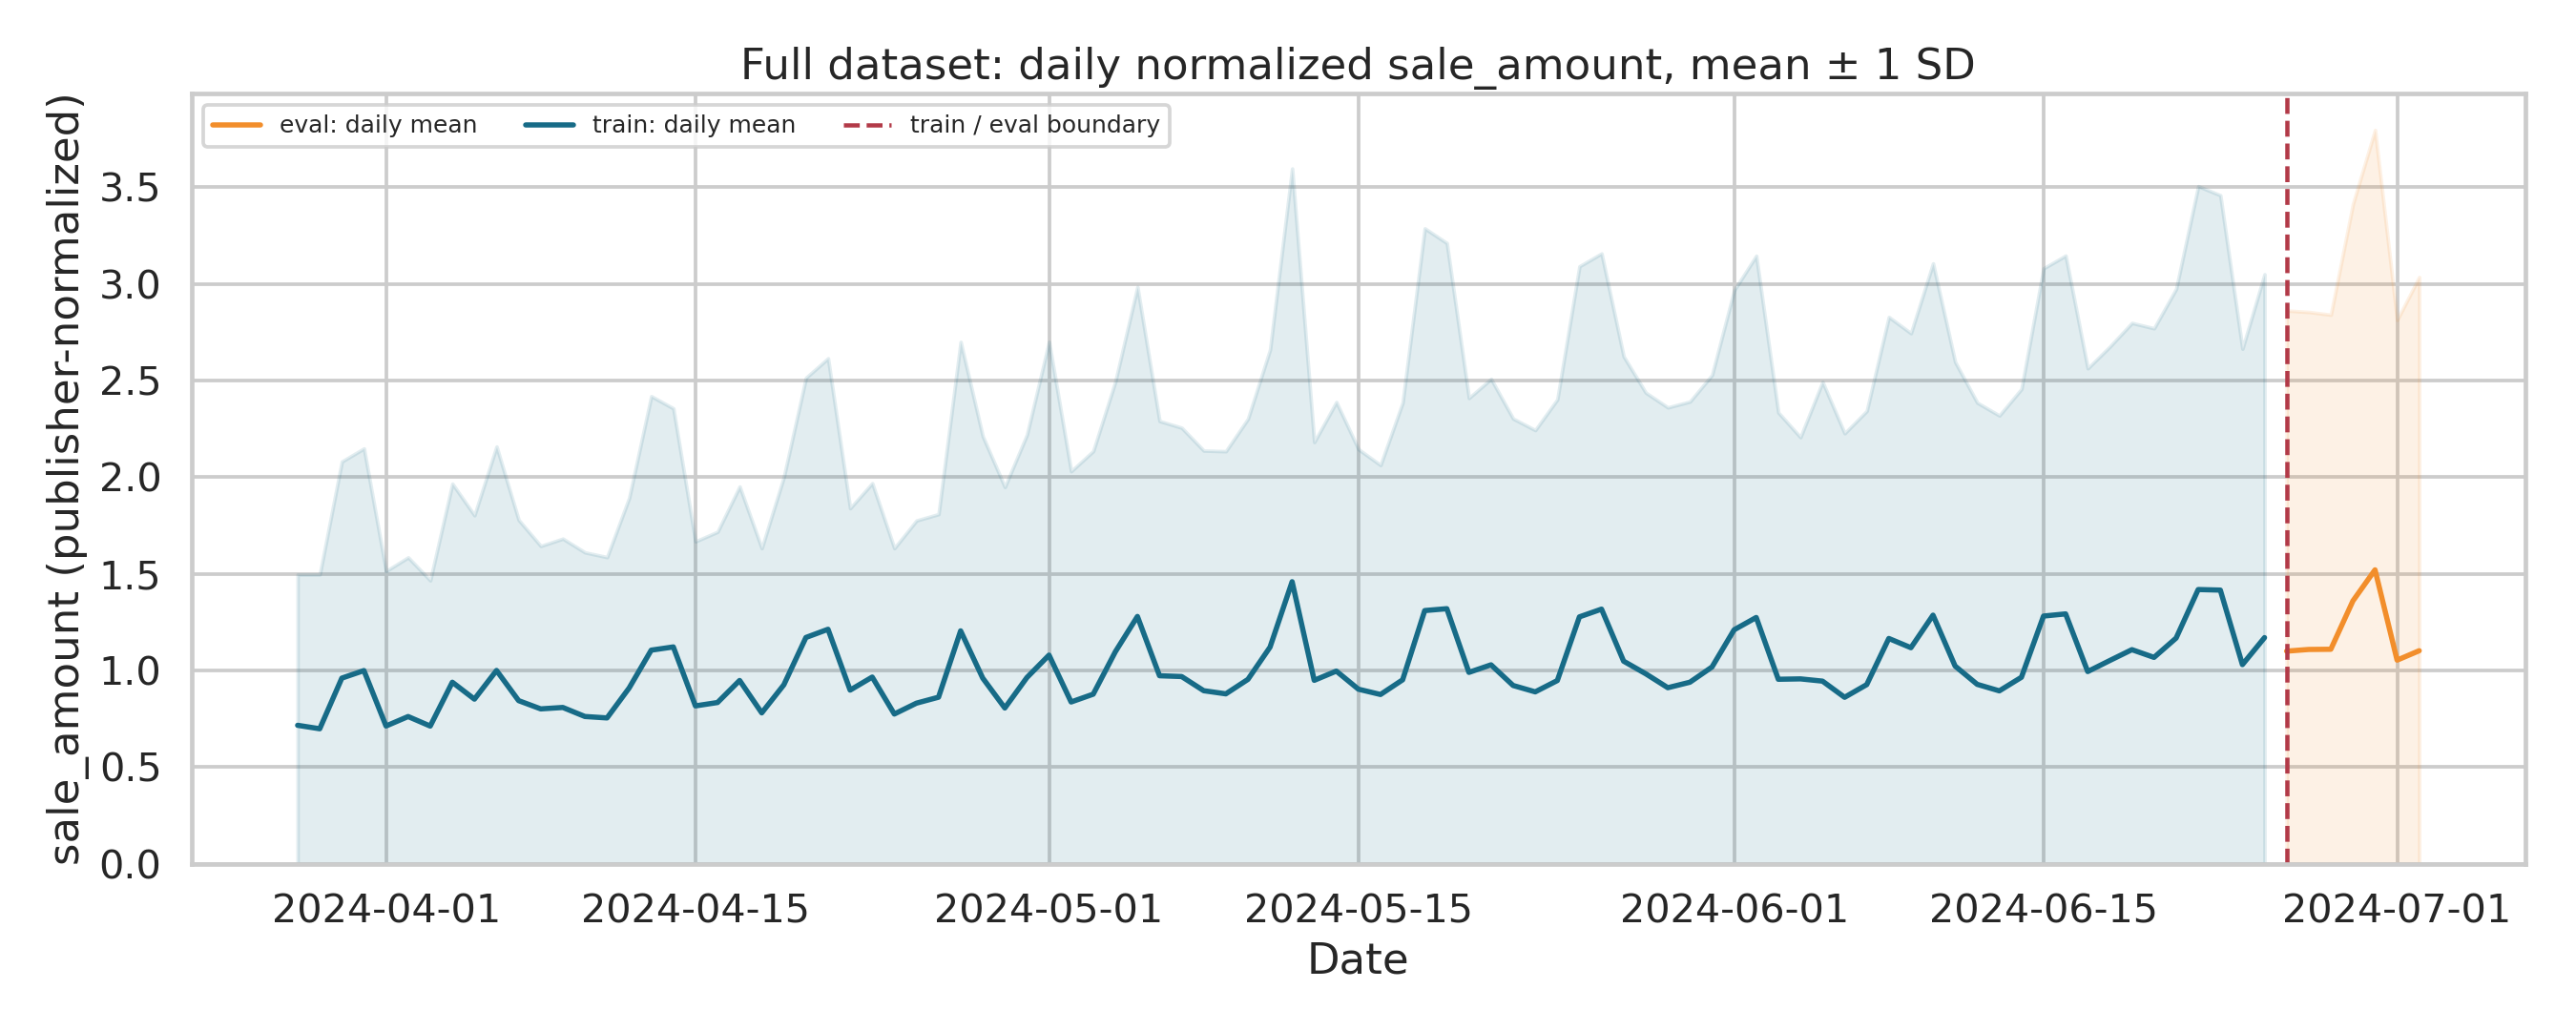

02_weekday_effect.png


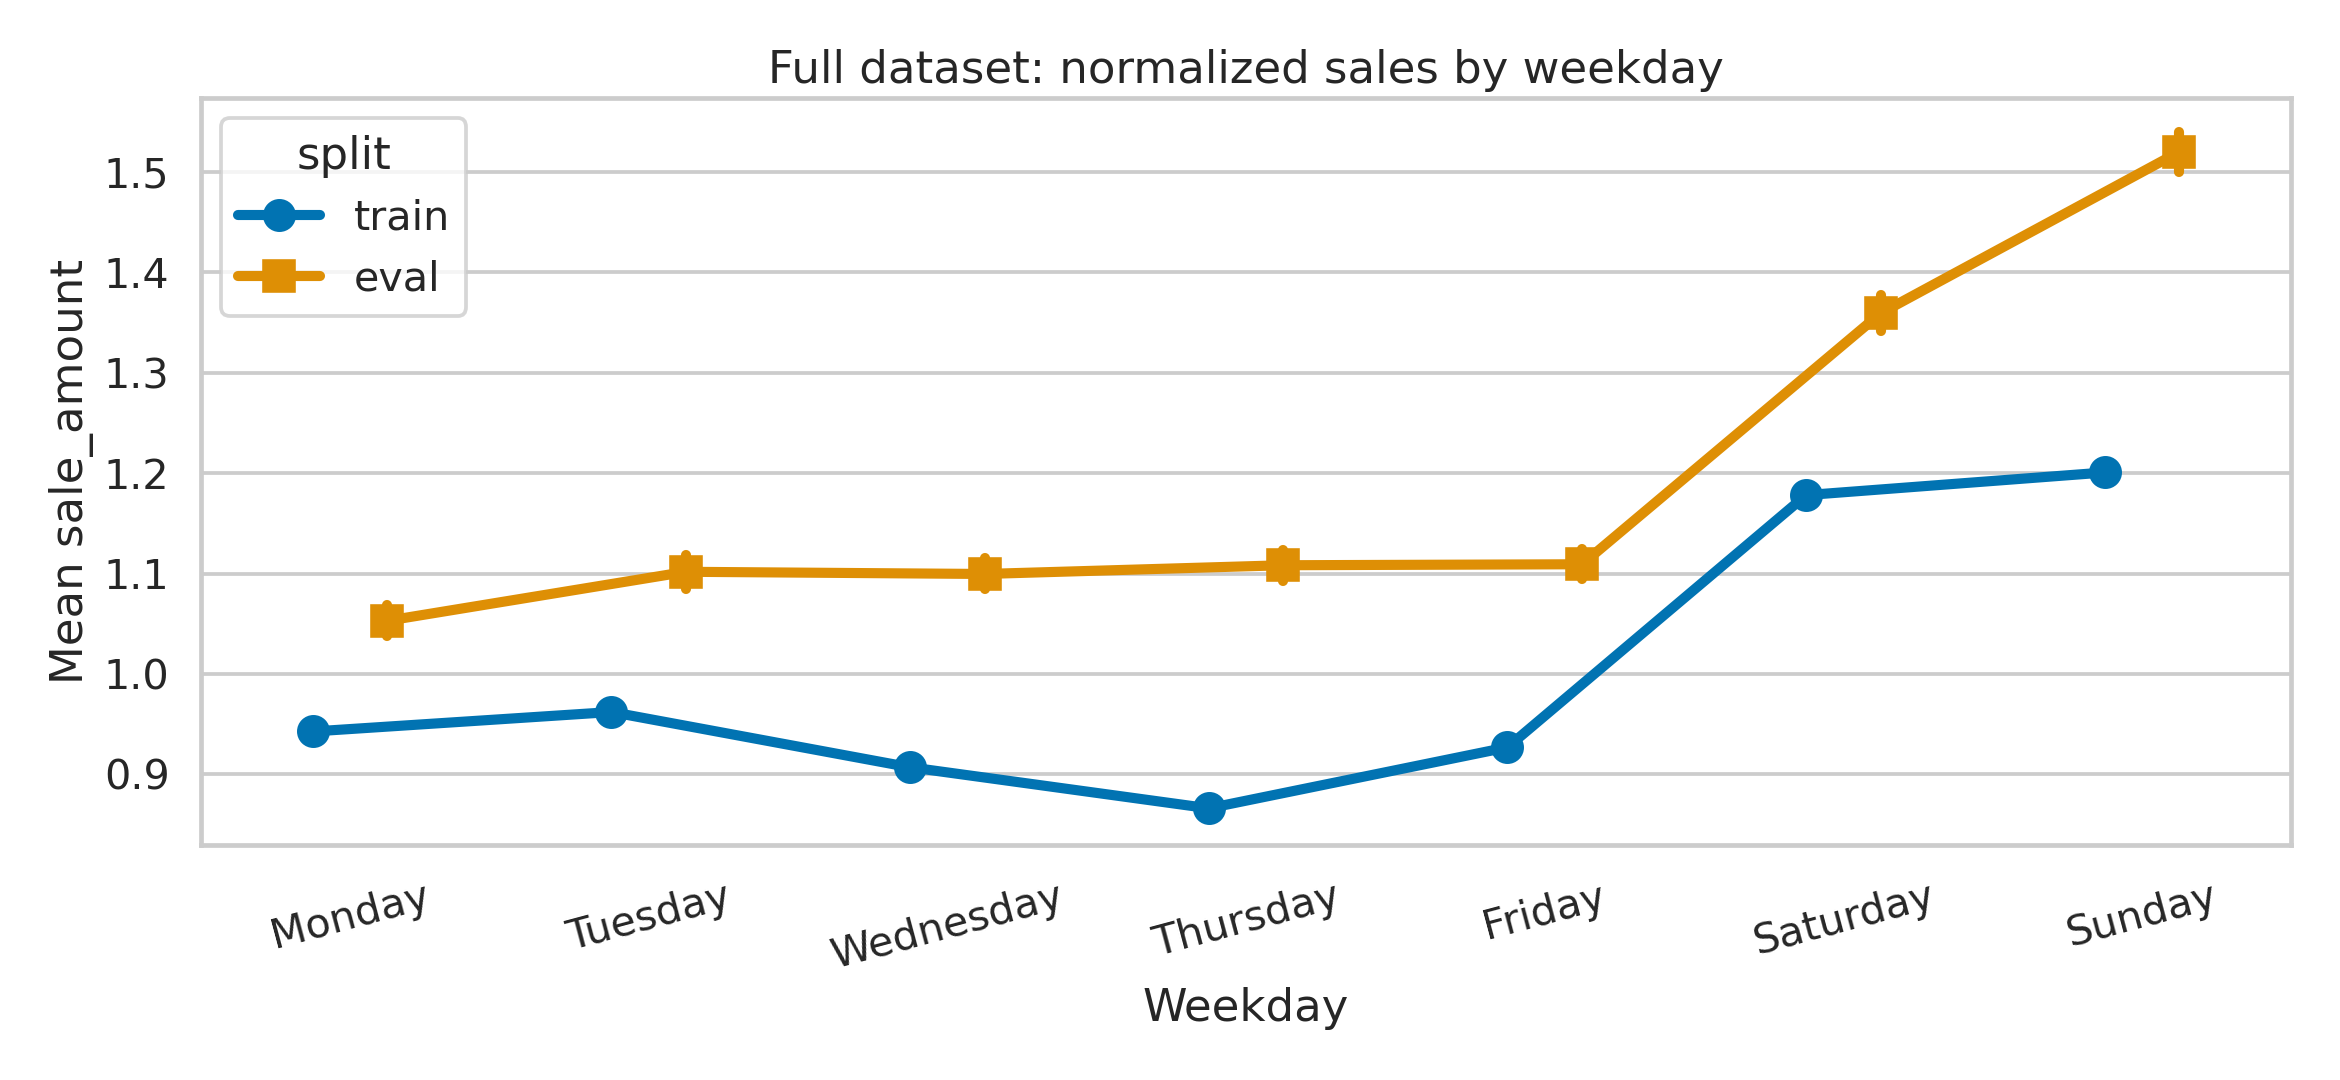

04_weekday_week_heatmap.png


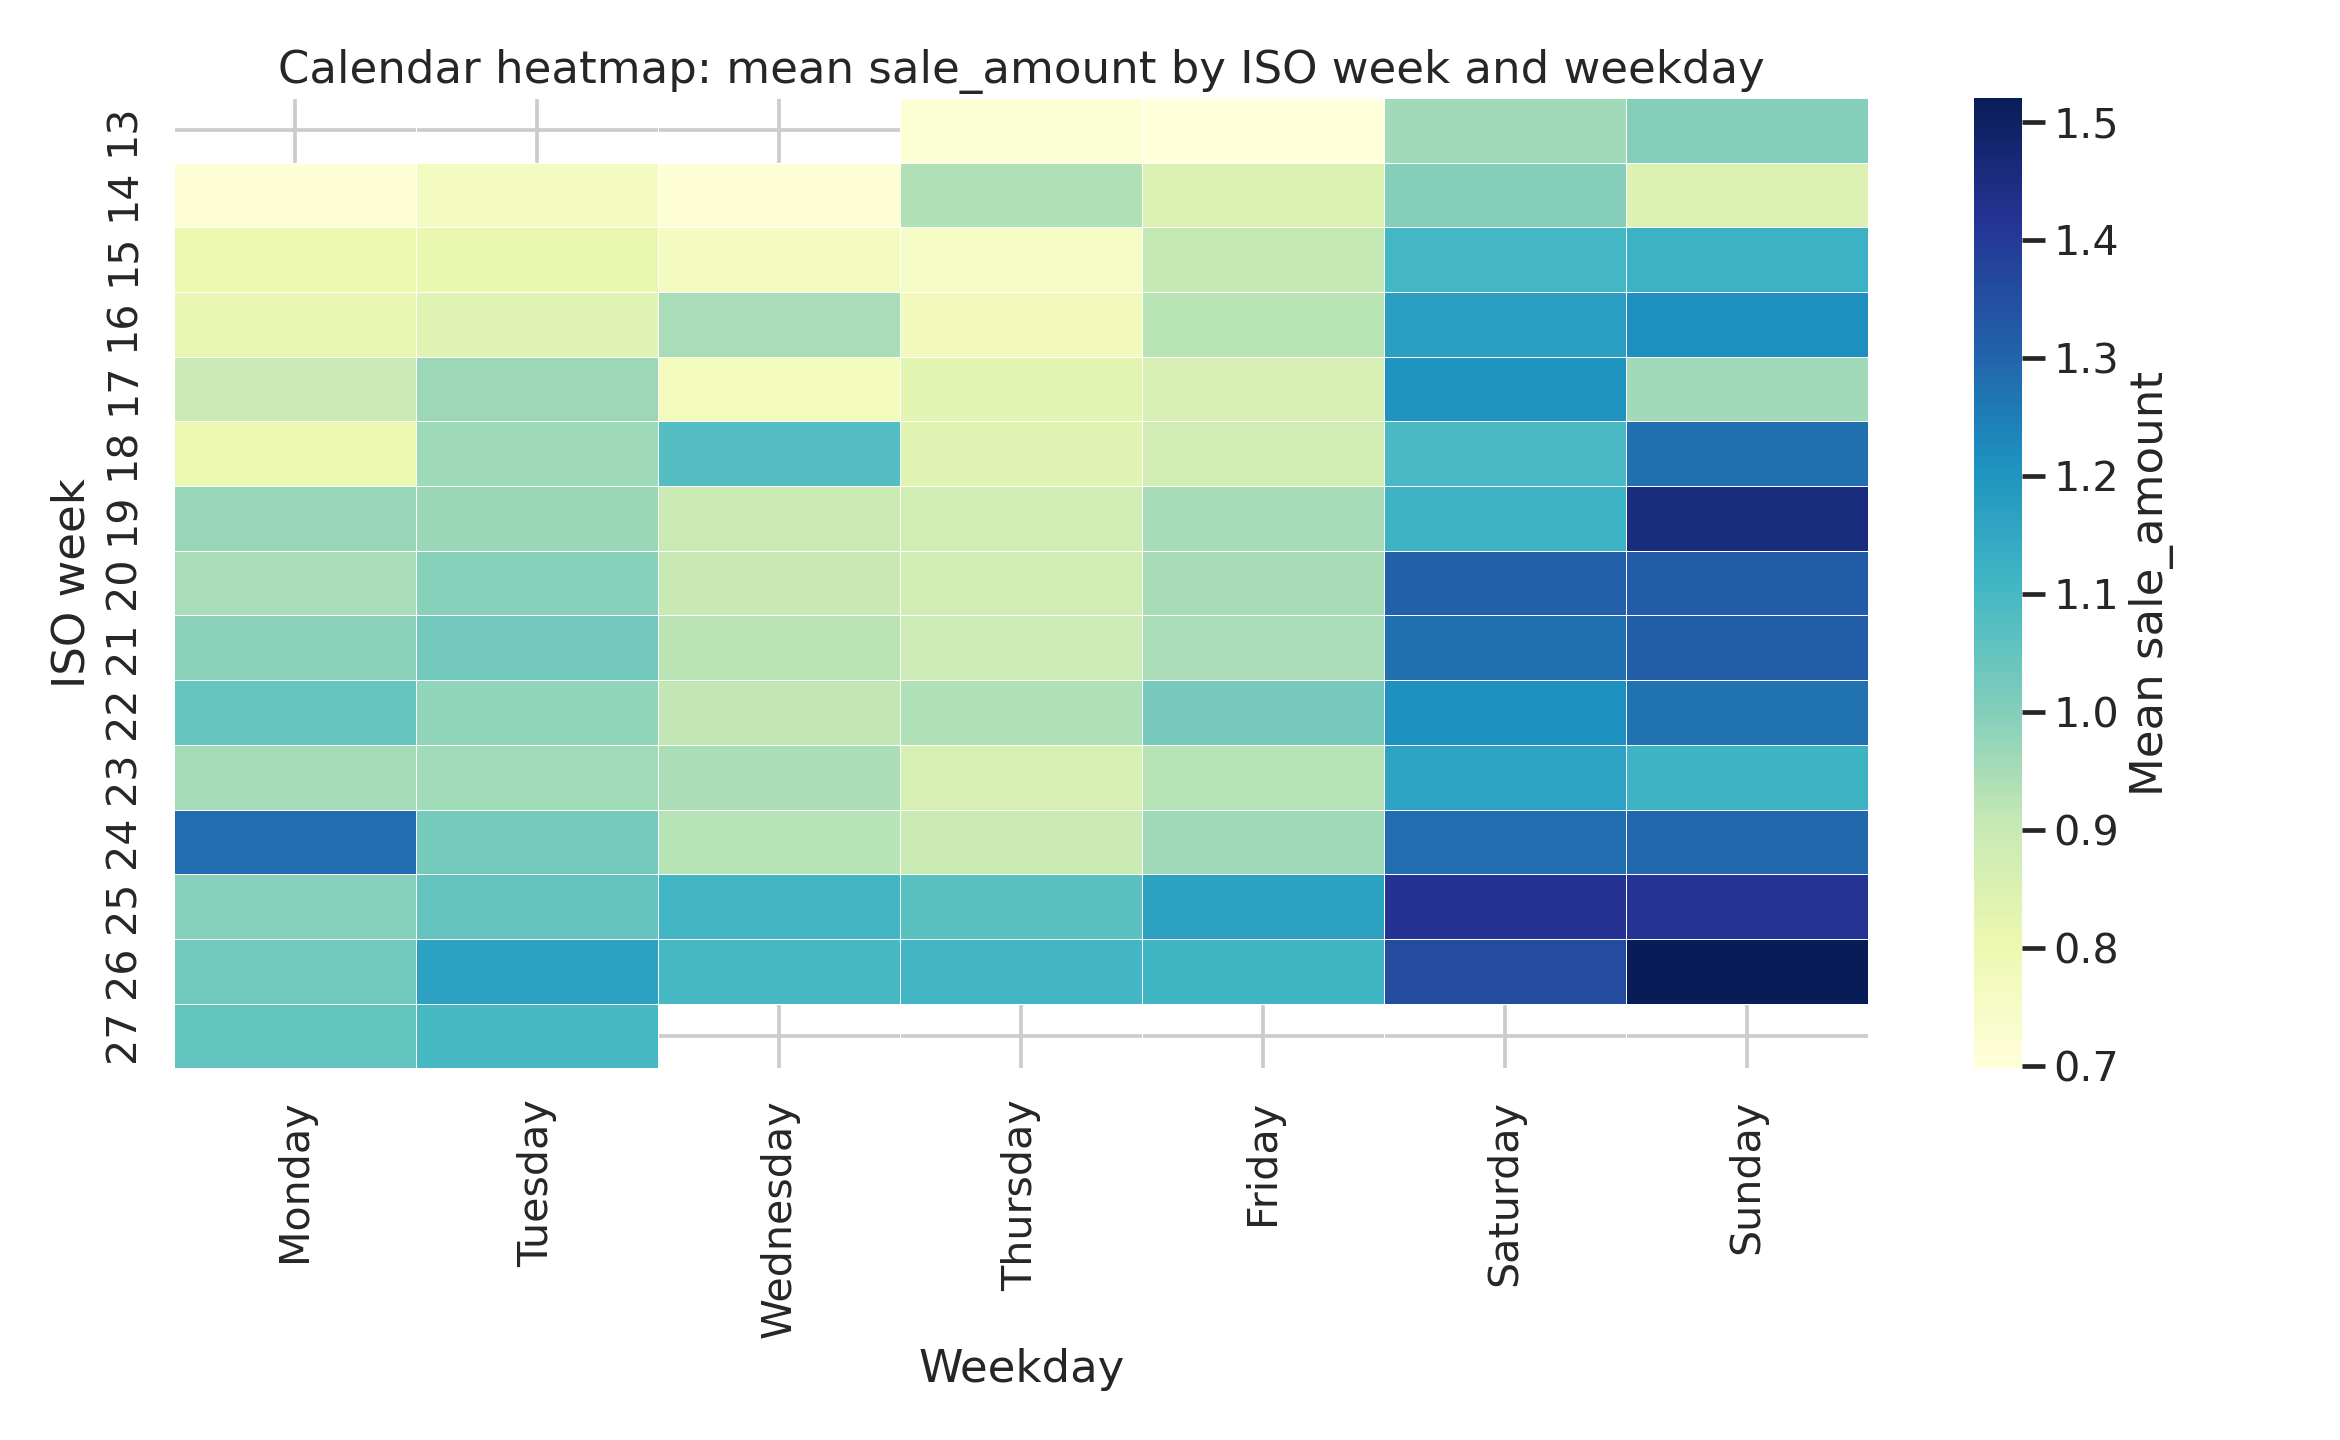

eval: mean sale_amount=1.1931; daily rows=350,000
train: mean sale_amount=0.9986; daily rows=4,500,000


split,eval,train
weekday_name,,
Friday,1.1092,0.9268
Monday,1.0530,0.9426
Saturday,1.3594,1.1781
Sunday,1.5202,1.2007
Thursday,1.1083,0.8660
Tuesday,1.1017,0.9620
Wednesday,1.0995,0.9069


In [8]:
for fn in ['01_full_daily_trend.png','02_weekday_effect.png','04_weekday_week_heatmap.png']:
    print(fn); display(Image(filename=str(eda/'figures'/fn)))
daily = pd.read_csv(eda/'daily_summary_all_rows.csv', parse_dates=['dt'])
weekday = pd.read_csv(eda/'weekday_summary_all_rows.csv')
for split, g in daily.groupby('split'):
    avg = np.average(g['mean_sale'], weights=g['n'])
    print(f'{split}: mean sale_amount={avg:.4f}; daily rows={g.n.sum():,}')
display(weekday.pivot(index='weekday_name',columns='split',values='mean_sale').round(4))

### 3.2. Phân phối và khác biệt theo nhãn hết hàng

03_target_distribution.png


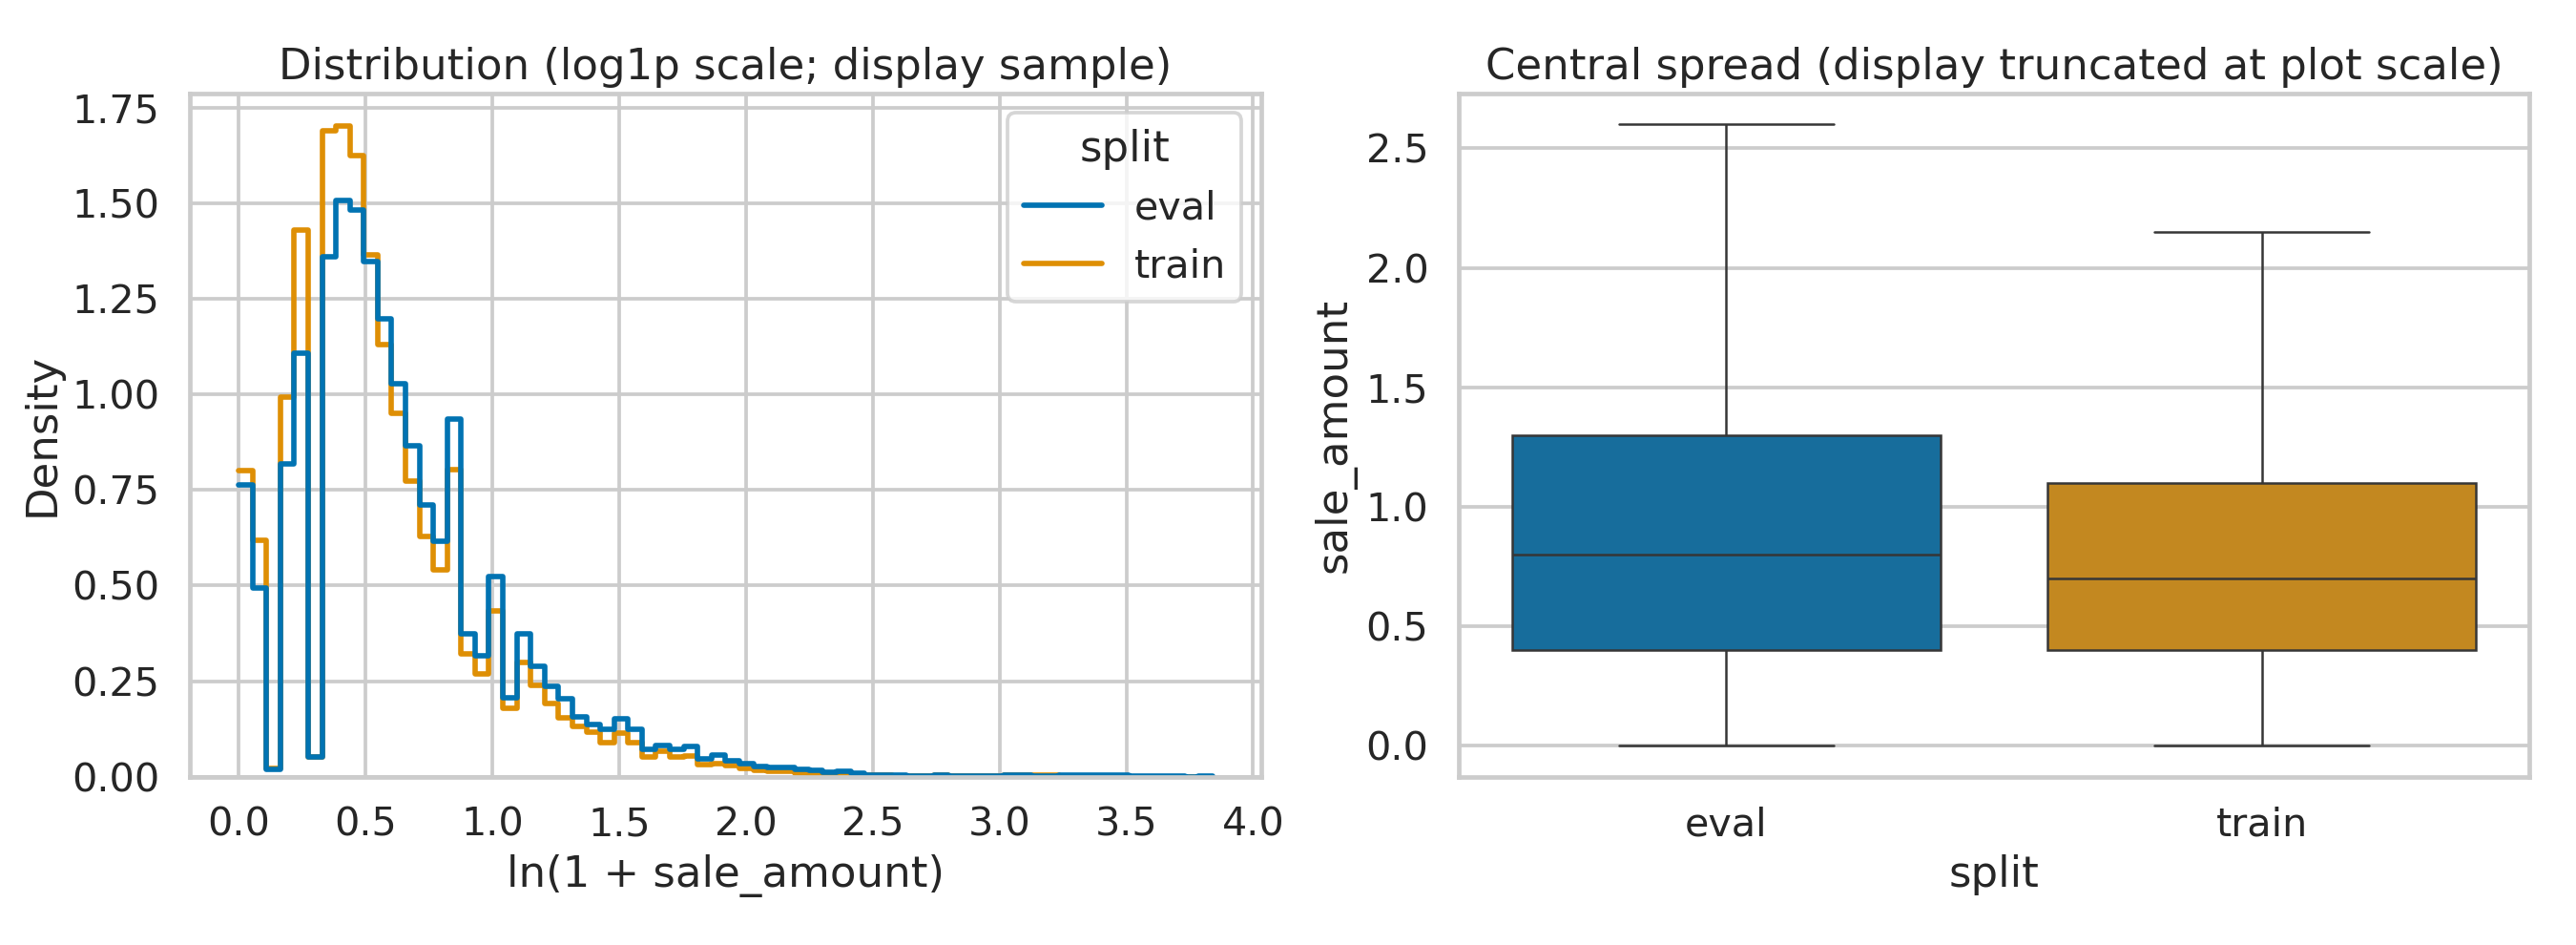

05_stockout_composition.png


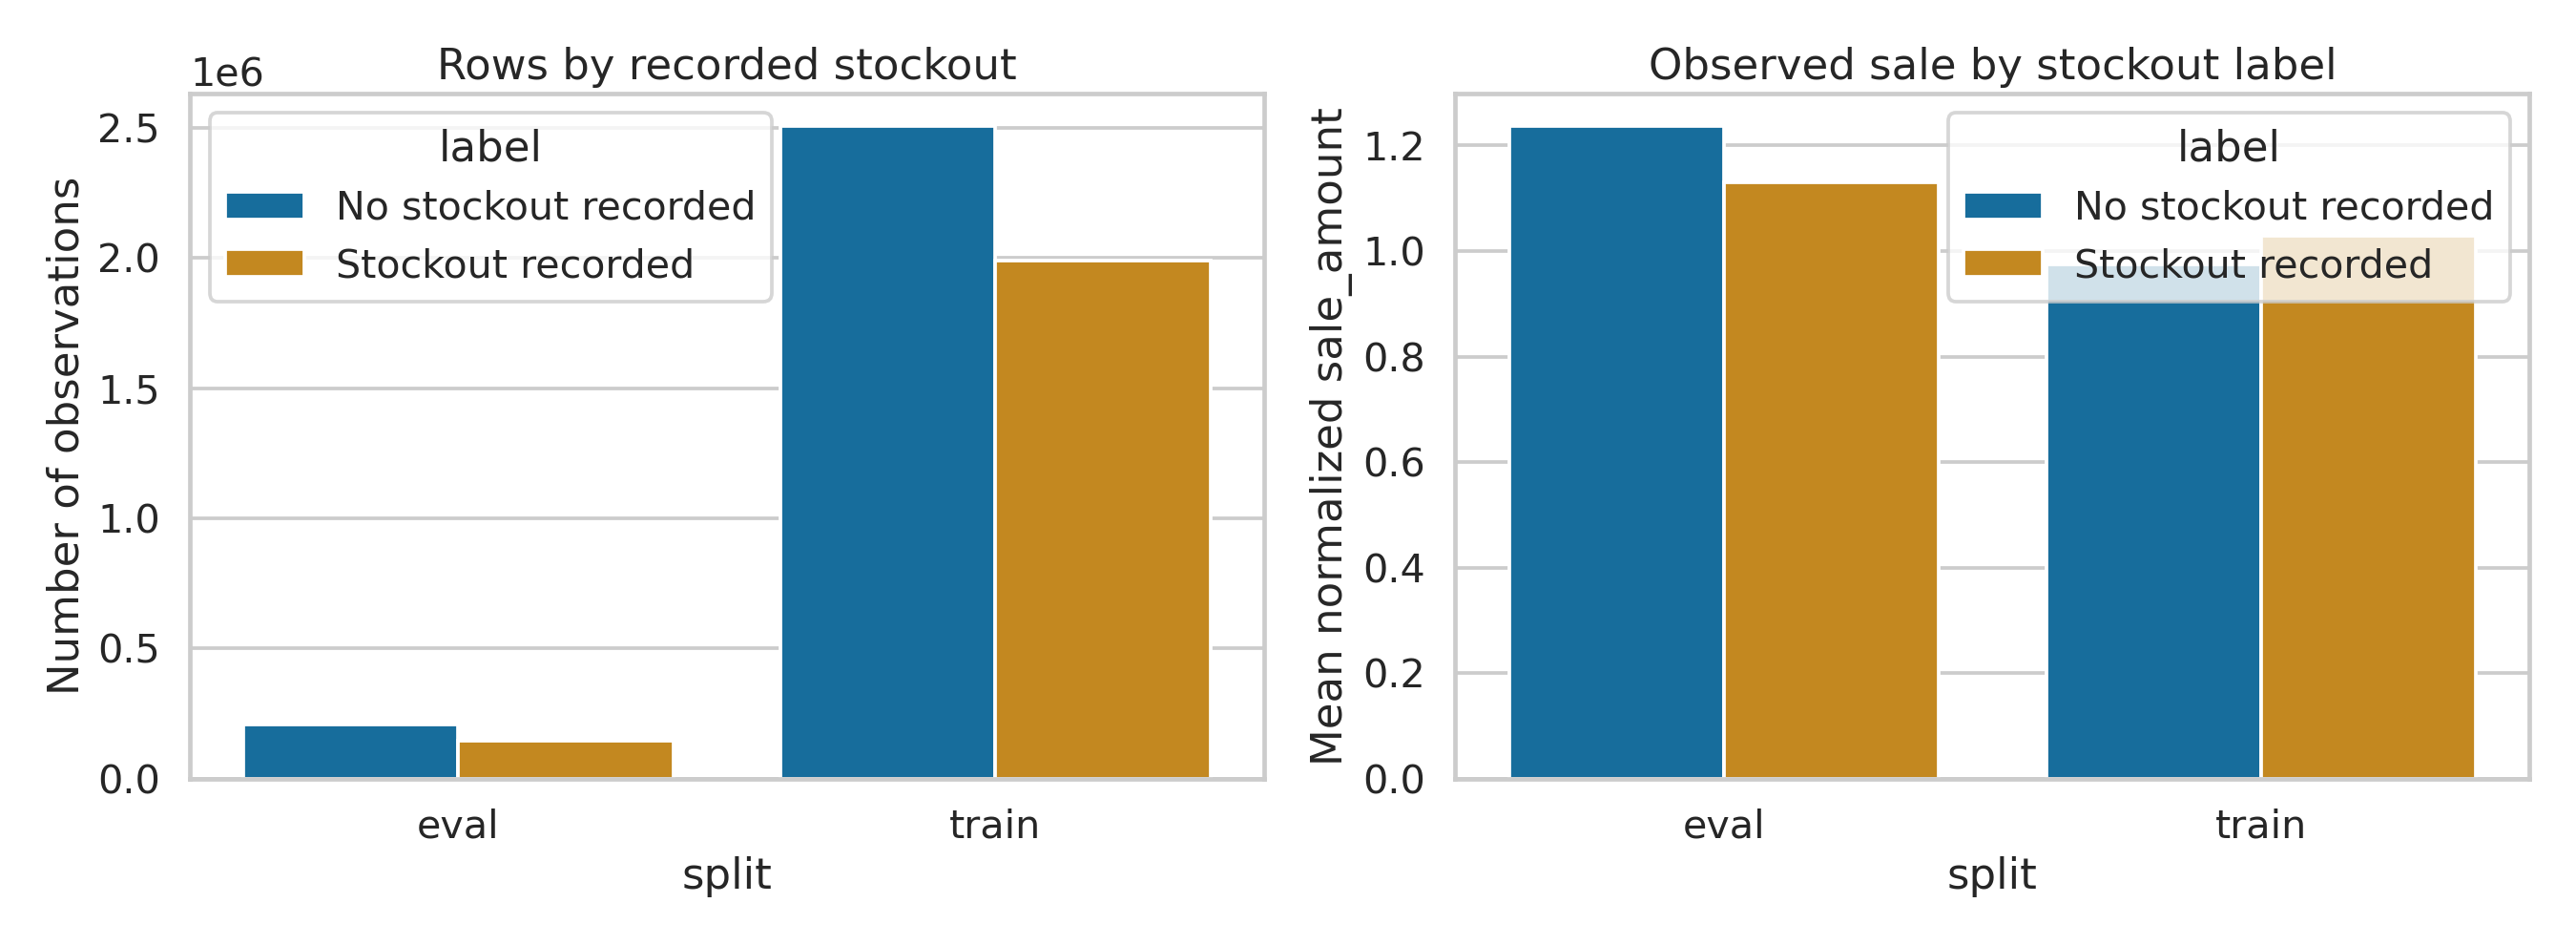

,split,stockout_recorded,n,mean_sale,median_sale,sale_std,zero_sale_rate
0,eval,False,206562,1.2371,0.7000,2.1260,1.84%
1,eval,True,143438,1.1296,0.8000,1.5495,7.51%
2,train,False,2507994,0.9745,0.6800,1.2758,1.87%
3,train,True,1992006,1.0289,0.7000,1.5554,7.72%


In [9]:
for fn in ['03_target_distribution.png','05_stockout_composition.png']:
    print(fn); display(Image(filename=str(eda/'figures'/fn)))
status = pd.read_csv(eda/'stockout_summary_all_rows.csv')
display(status.style.format({'mean_sale':'{:.4f}','median_sale':'{:.4f}','sale_std':'{:.4f}','zero_sale_rate':'{:.2%}'}))

### 3.3. Ngành hàng, chiết khấu và tương quan

06_category_comparison.png


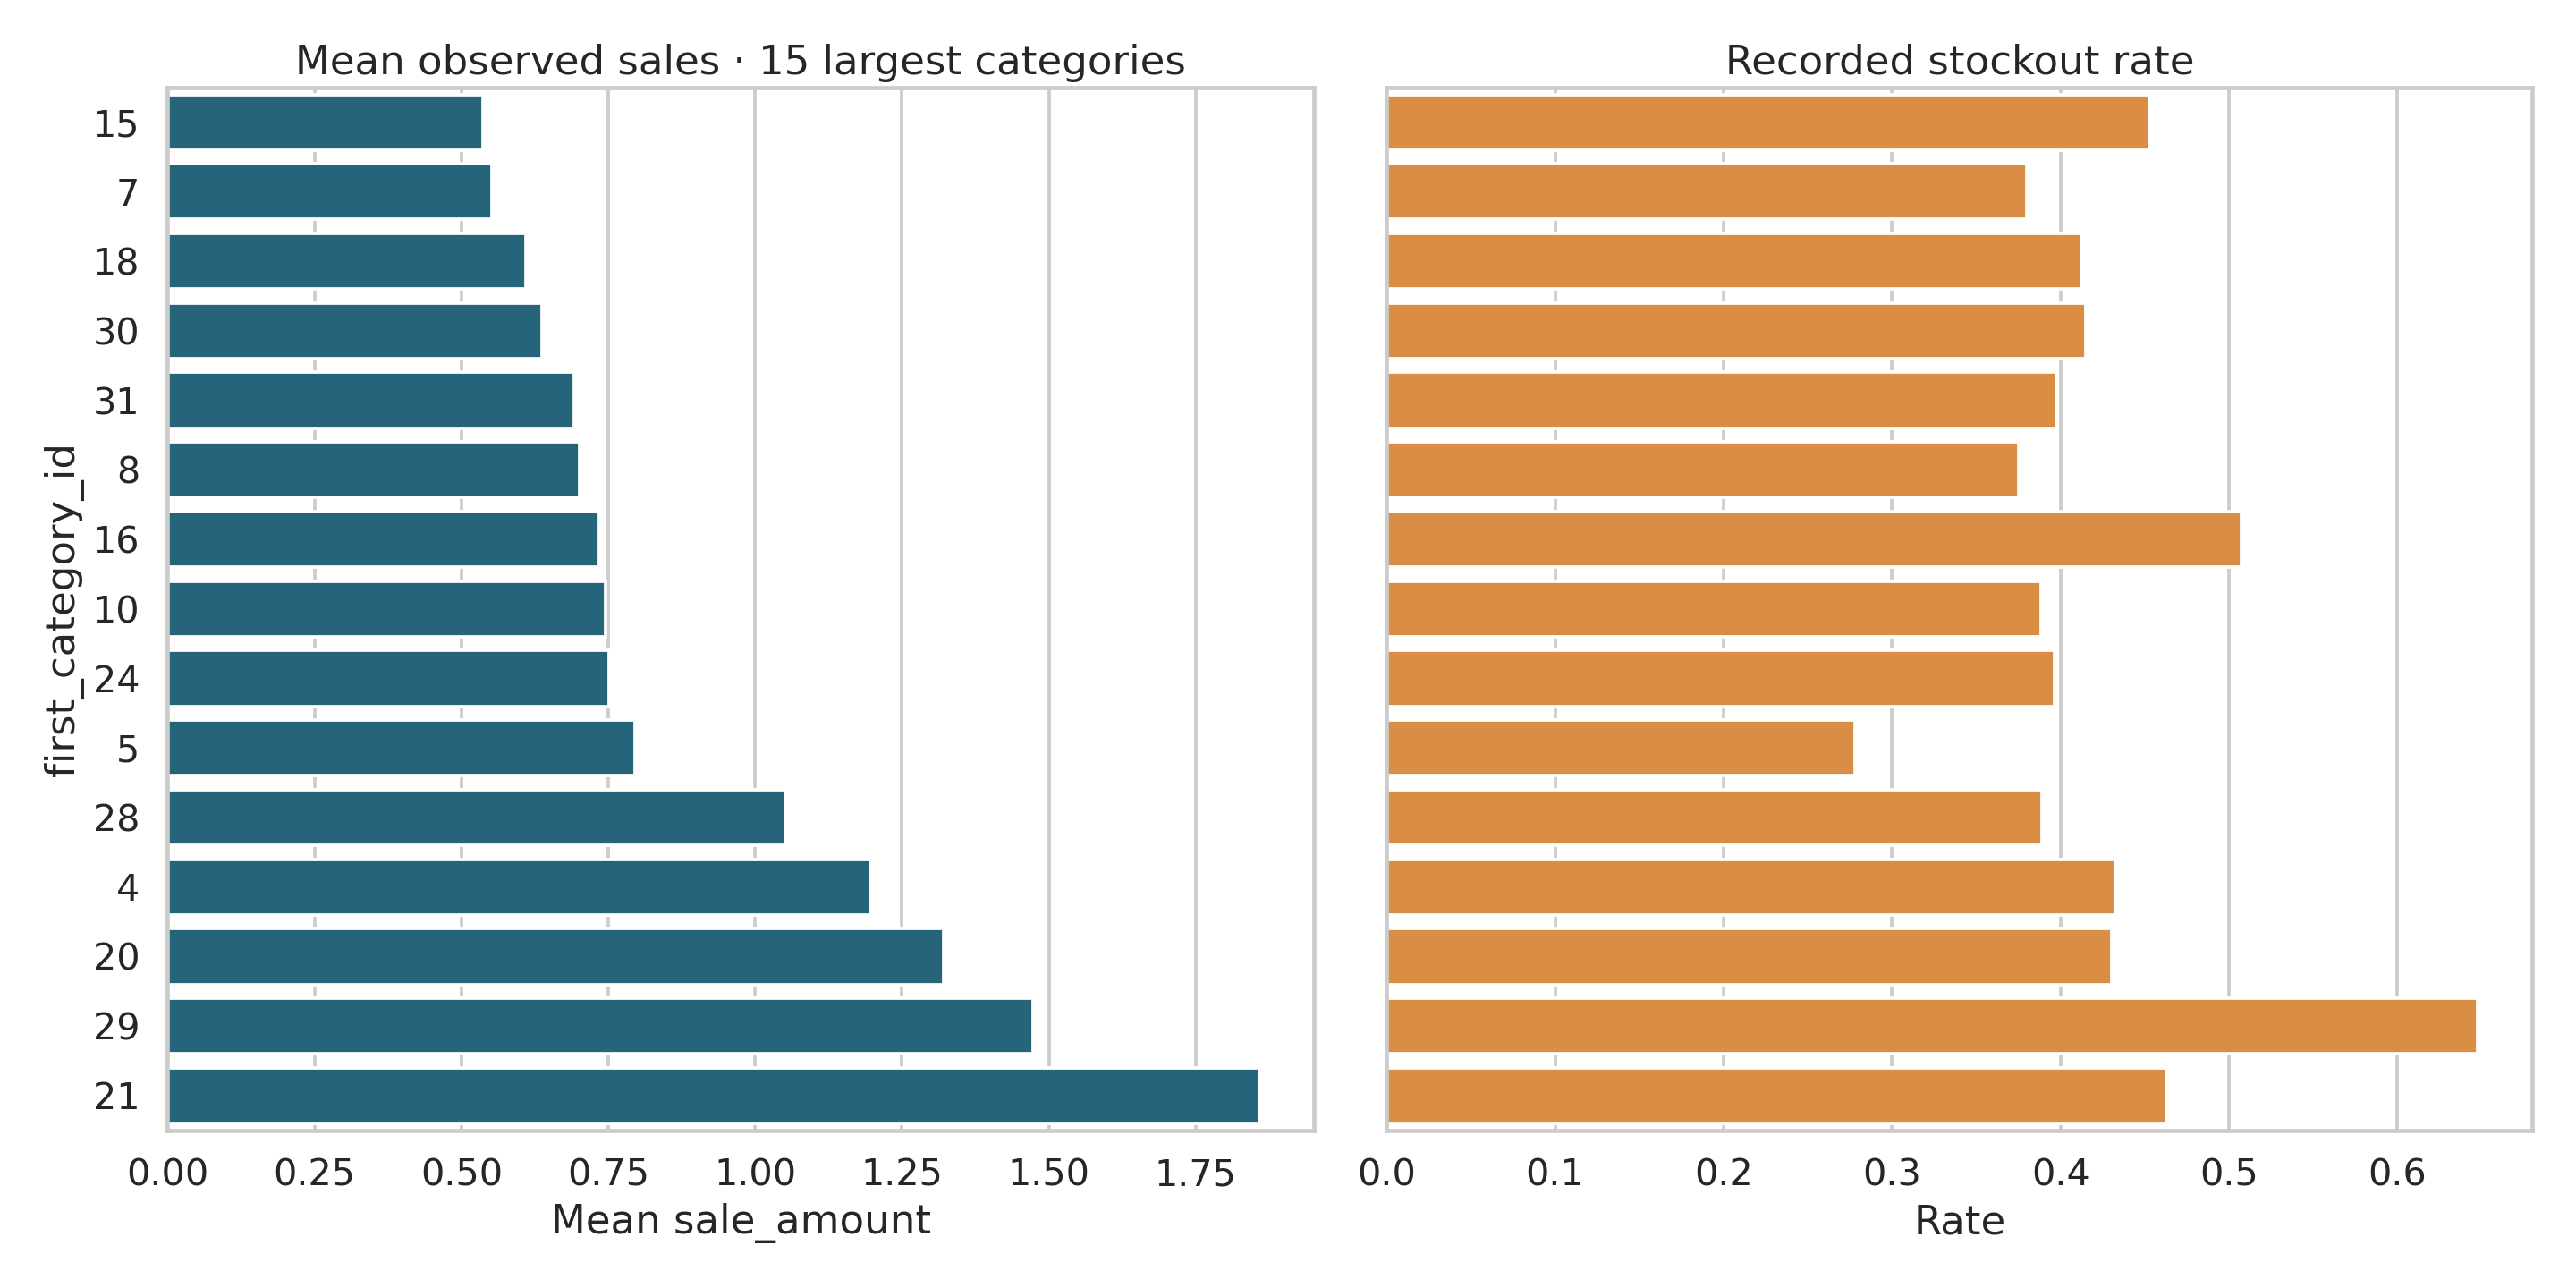

07_discount_relationship.png


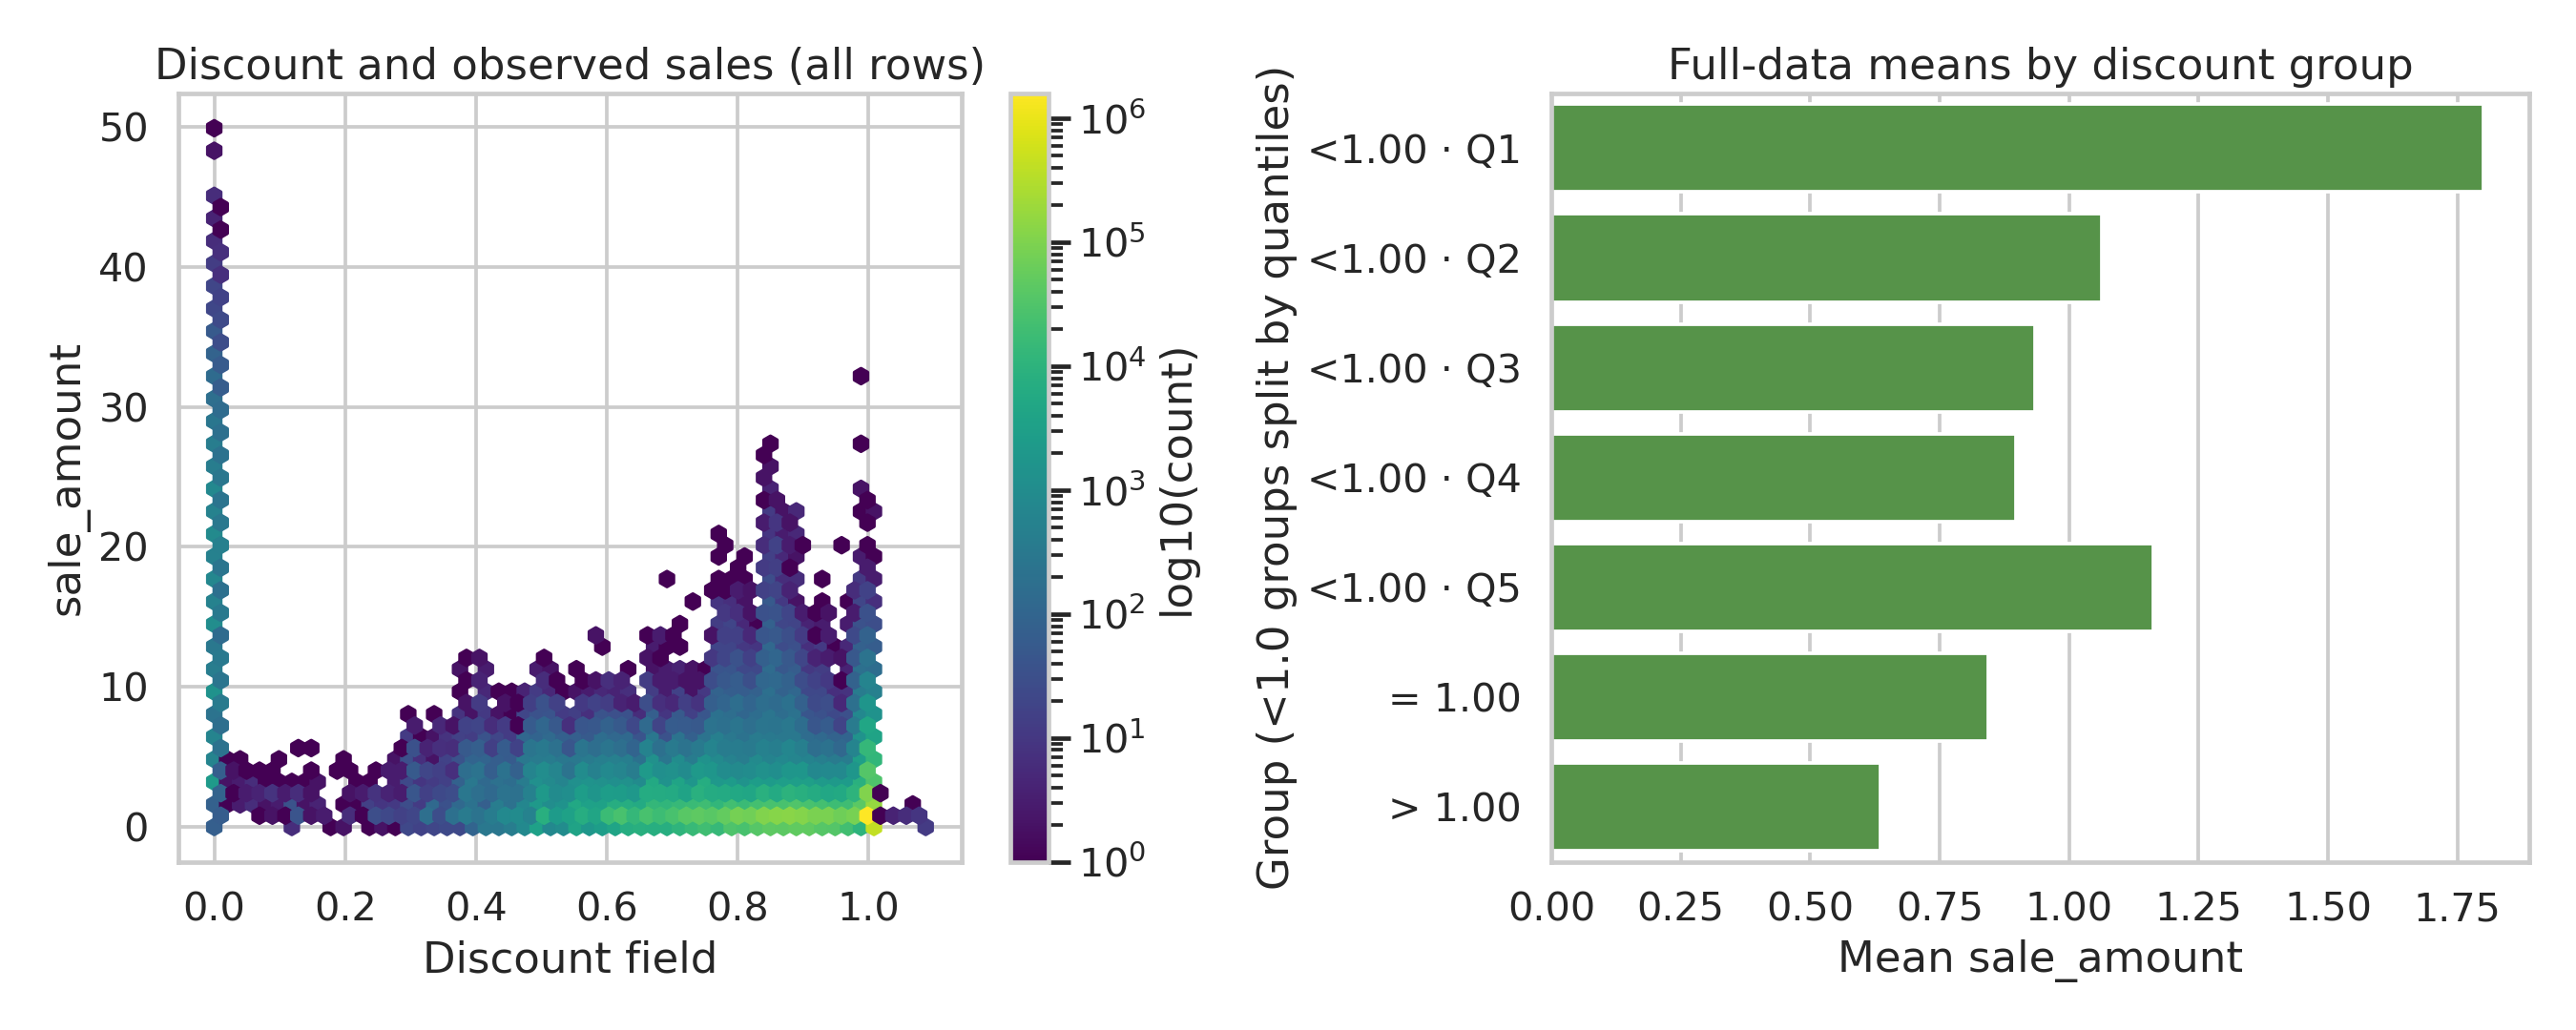

08_numeric_correlation.png


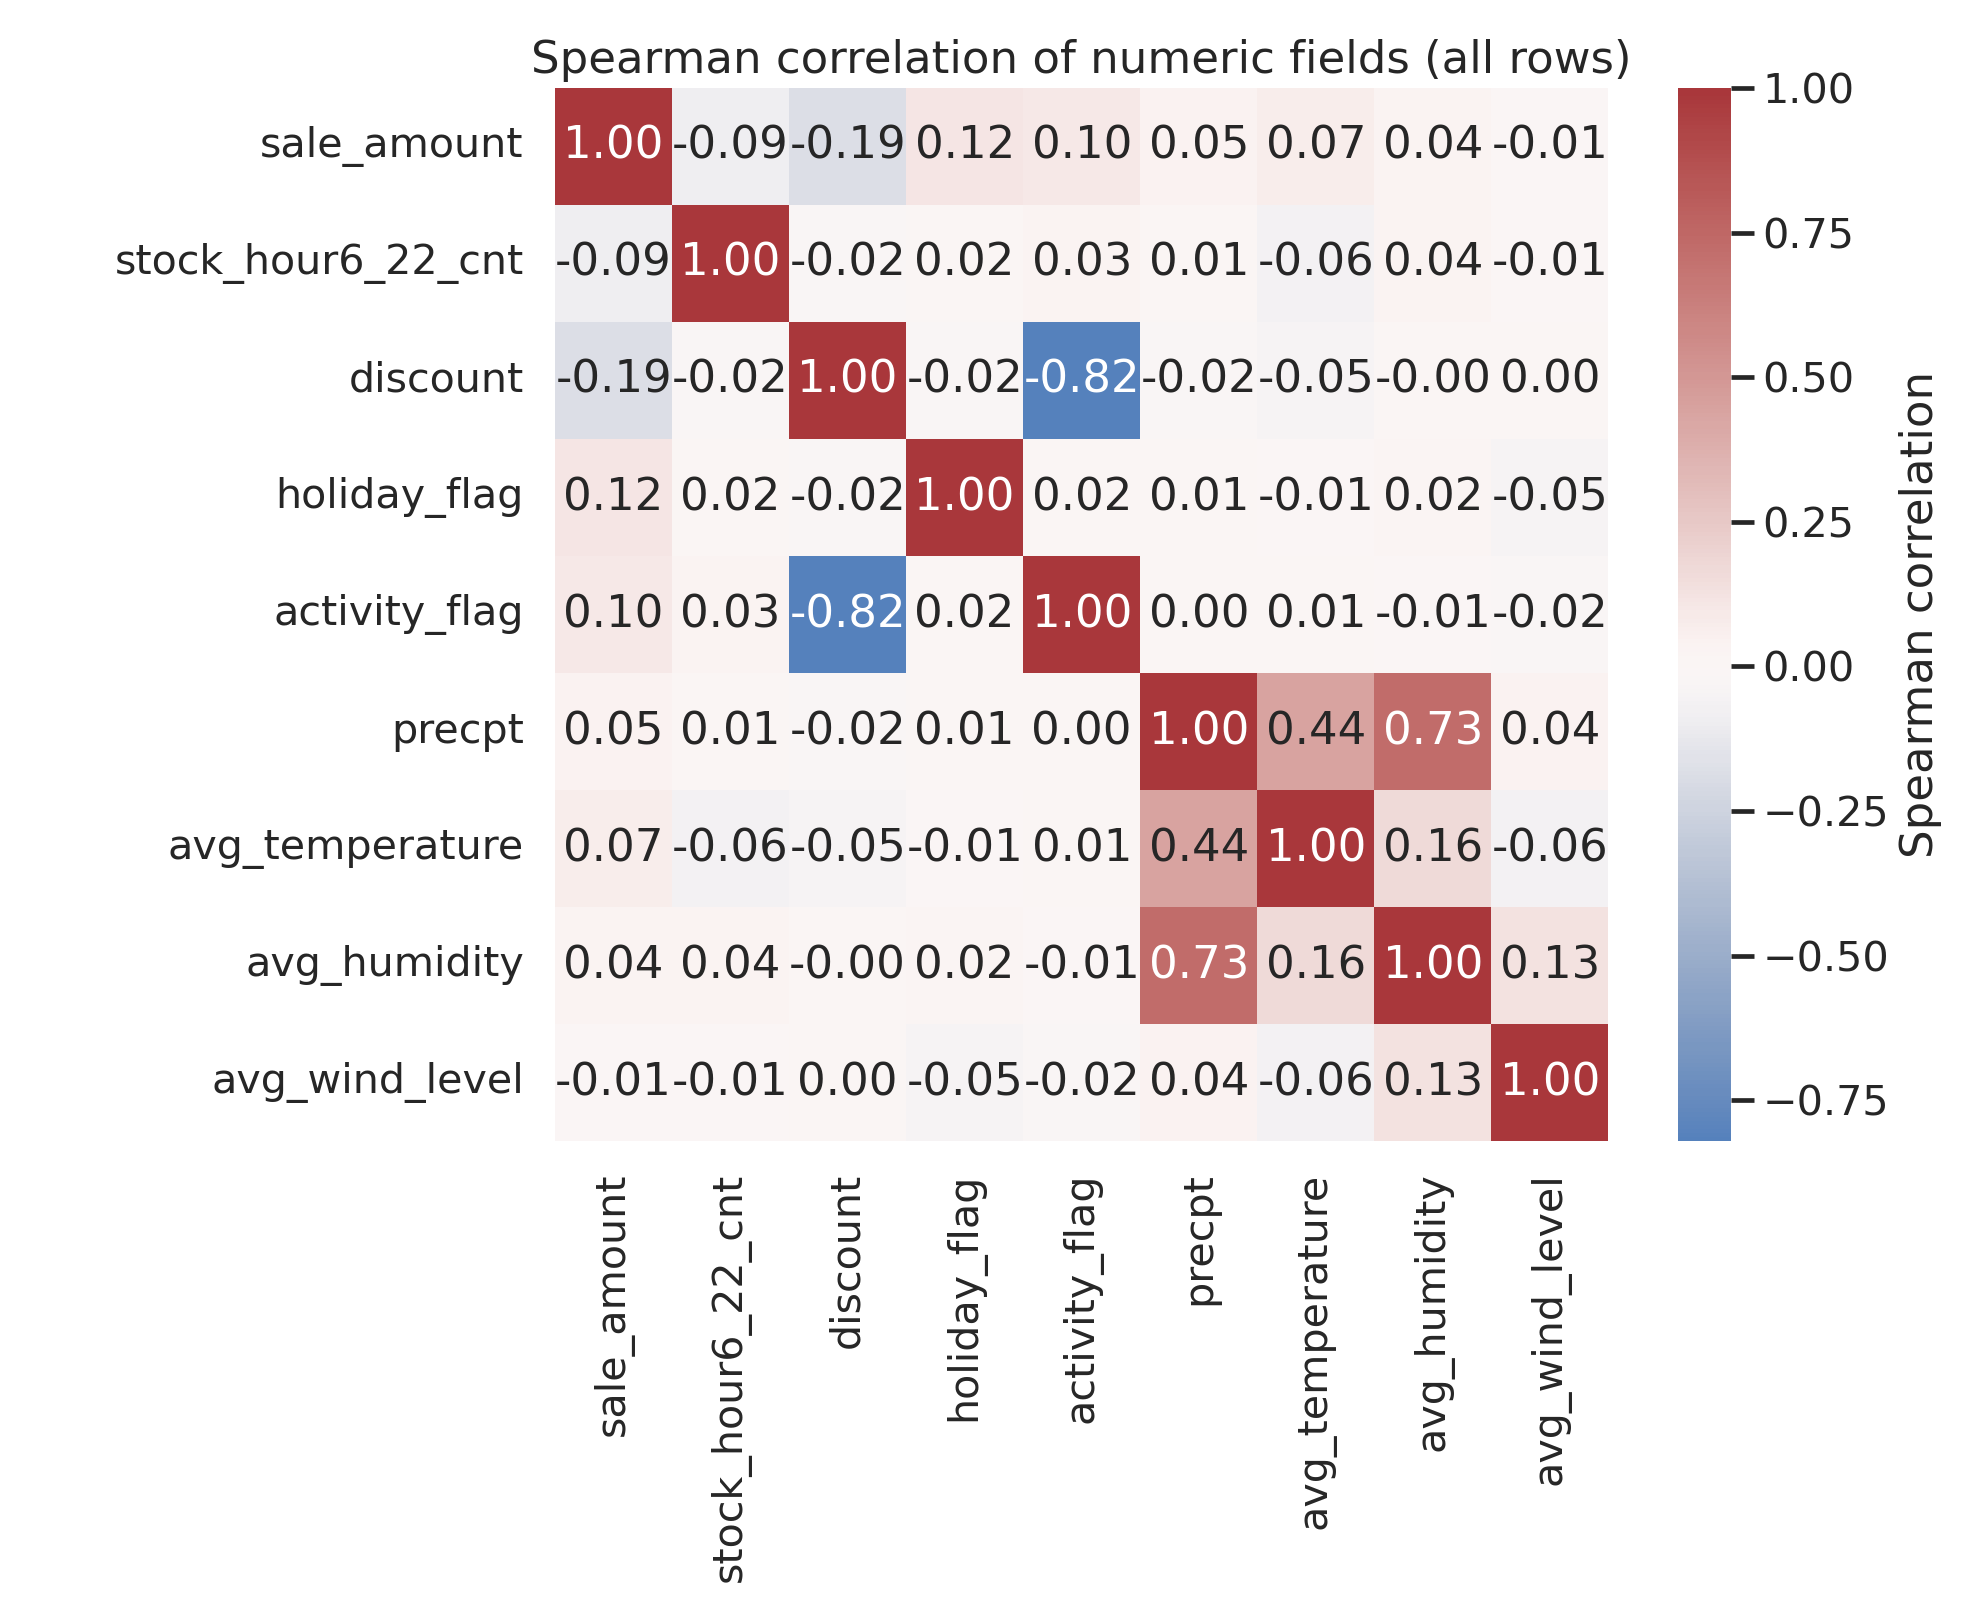

,first_category_id,n,mean_sale,median_sale,stockout_rate,mean_discount
4,4,1056136,1.1965,0.8000,43.27%,0.8900
16,16,696169,0.7343,0.6000,50.75%,0.9206
20,20,536701,1.3212,0.9000,43.05%,0.8832
29,29,339112,1.4734,1.0000,64.77%,0.9381
8,8,279845,0.7007,0.6000,37.54%,0.9198
21,21,275771,1.8582,0.6000,46.26%,0.8680
10,10,275286,0.7450,0.6000,38.83%,0.9376
18,18,227853,0.6101,0.5000,41.26%,0.9296
28,28,193806,1.0516,0.9000,38.91%,0.9575
31,31,185464,0.6917,0.6000,39.76%,0.9622


,discount_group,n,mean_sale,median_sale,stockout_rate
0,<1.00 · Q1,502882,1.799346,1.00,0.462612
1,<1.00 · Q2,496987,1.063188,0.80,0.461579
2,<1.00 · Q3,504168,0.934458,0.70,0.448767
3,<1.00 · Q4,496000,0.897615,0.70,0.467554
4,<1.00 · Q5,492012,1.163352,0.80,0.417567
5,= 1.00,2357917,0.843640,0.60,0.428252
6,> 1.00,34,0.635294,0.55,0.411765


In [10]:
for fn in ['06_category_comparison.png','07_discount_relationship.png','08_numeric_correlation.png']:
    print(fn); display(Image(filename=str(eda/'figures'/fn)))
cat = pd.read_csv(eda/'category_summary_all_rows.csv').sort_values('n',ascending=False)
display(cat.head(15).style.format({'mean_sale':'{:.4f}','median_sale':'{:.4f}','stockout_rate':'{:.2%}','mean_discount':'{:.4f}'}))
display(pd.read_csv(eda/'discount_bin_summary_all_rows.csv'))

### 3.4. Một số chuỗi thực tế để xem hình dạng

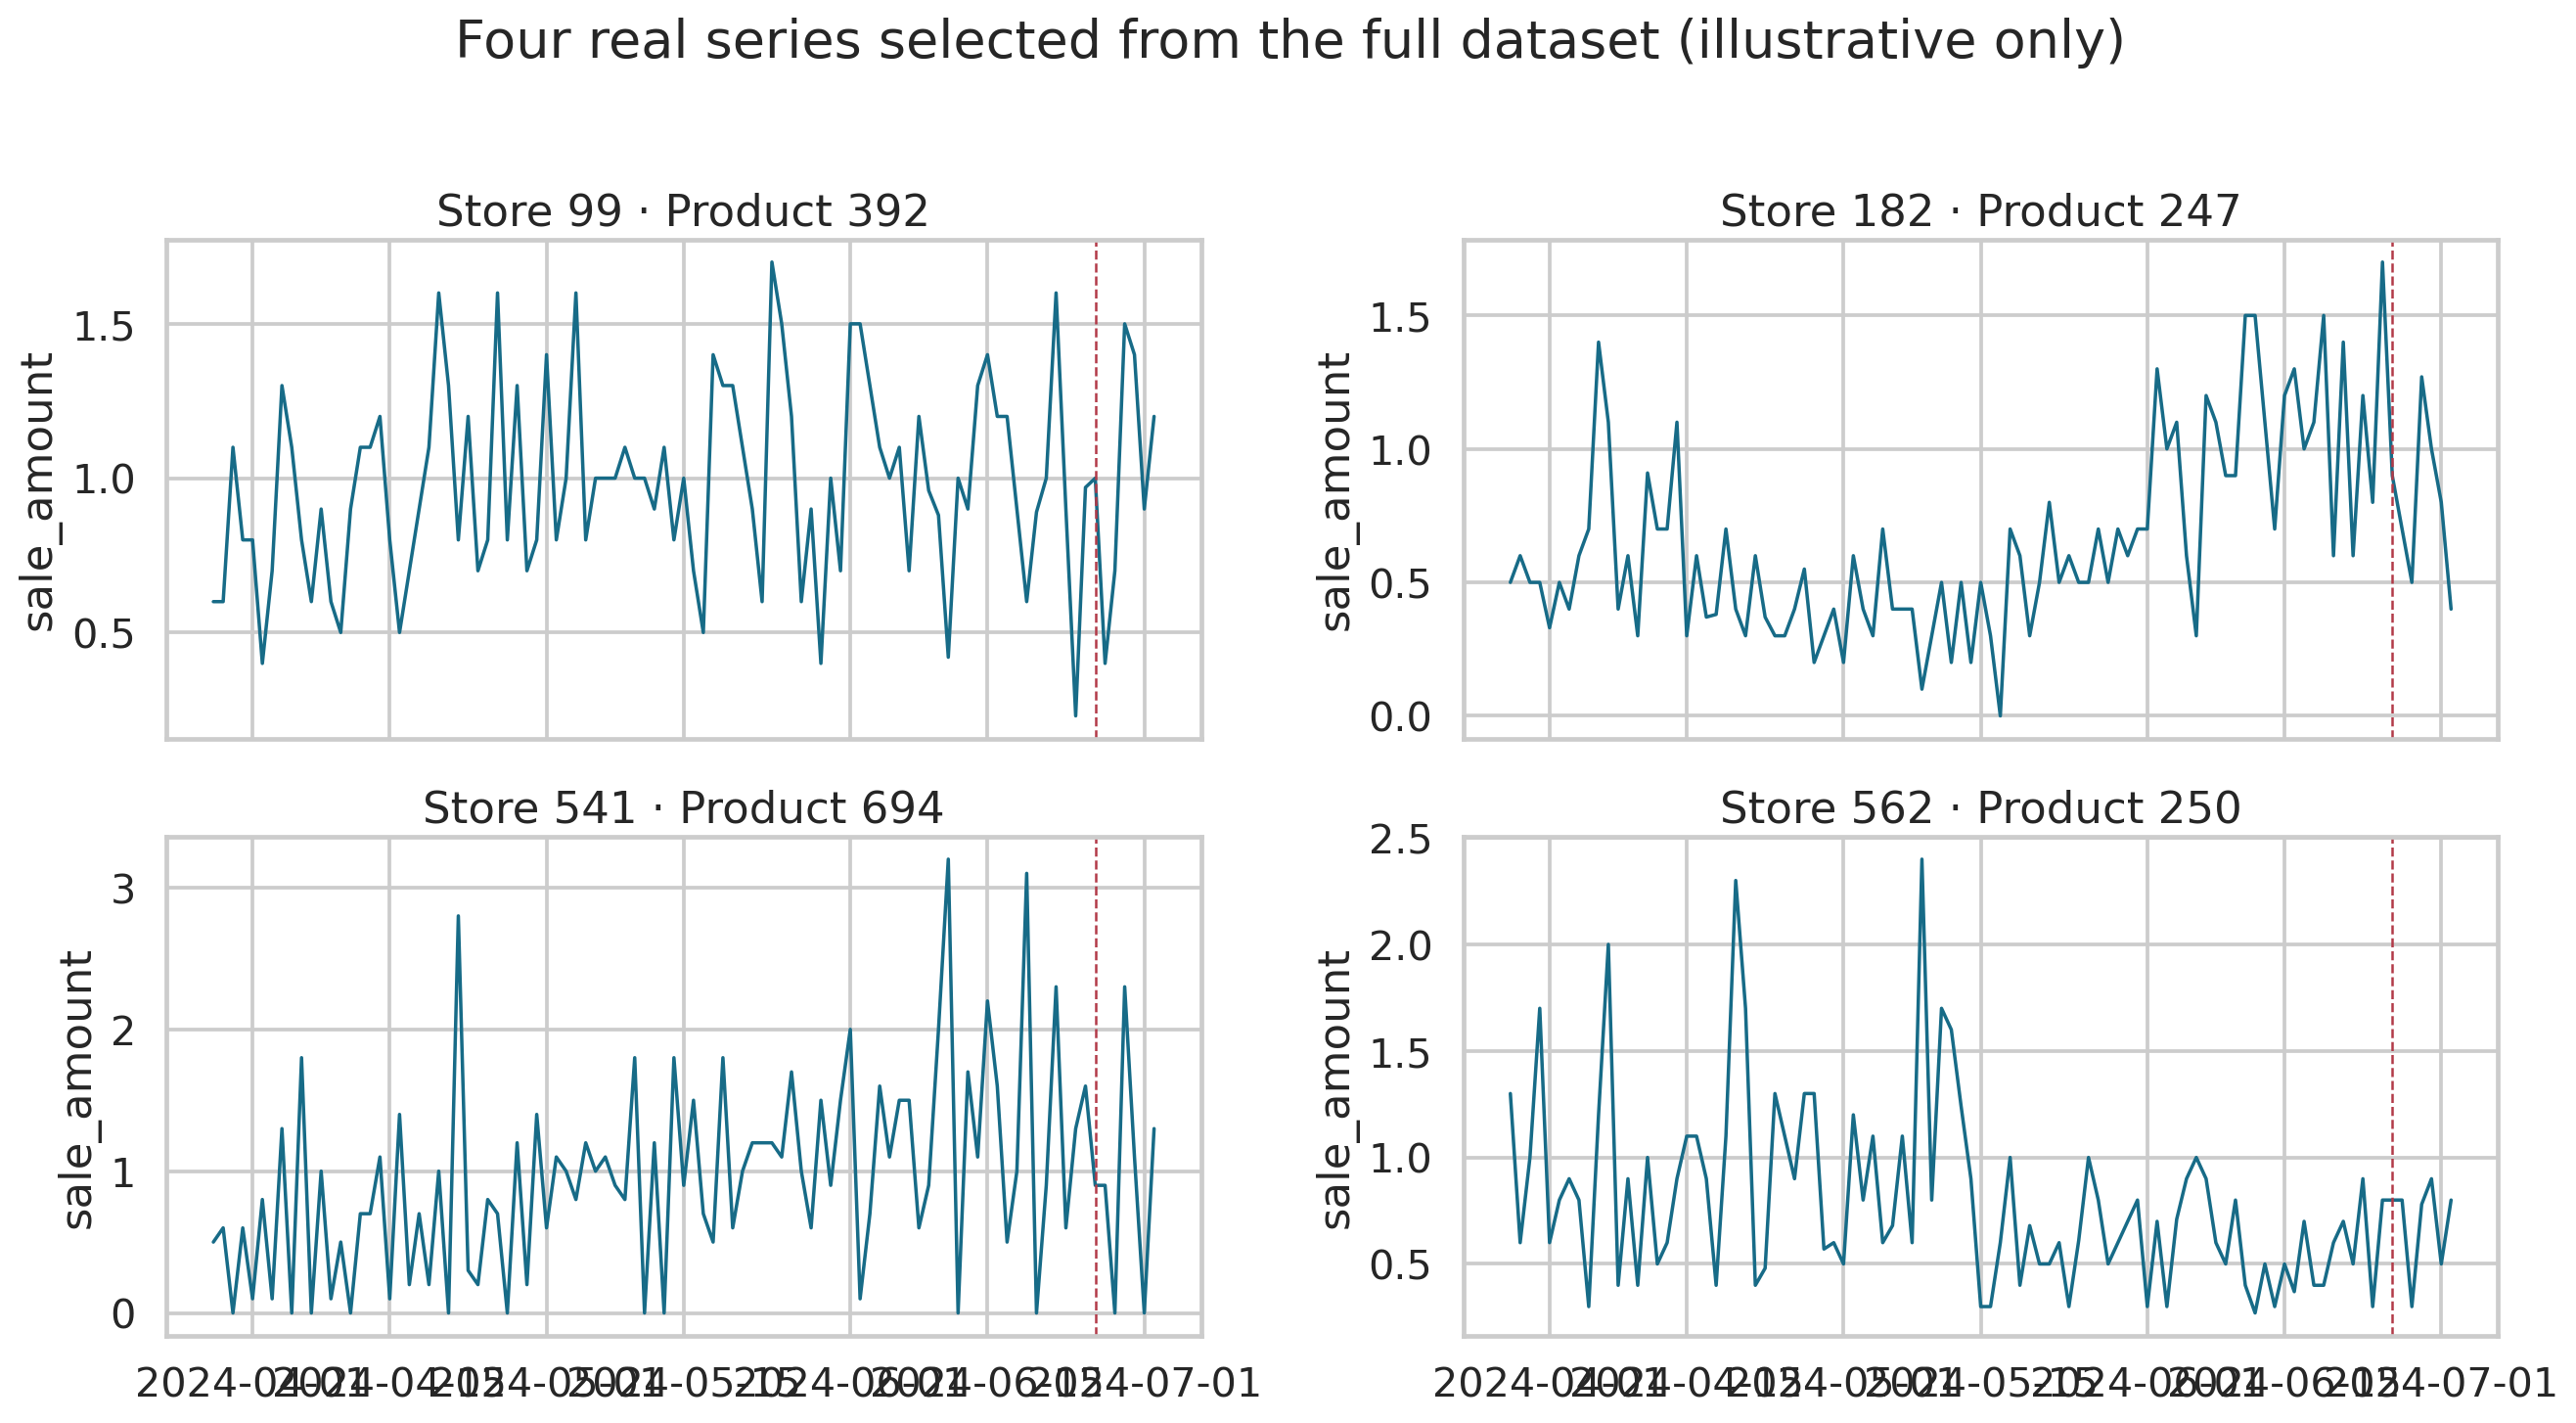

Các đường này là ví dụ minh họa; không thay thế thống kê gộp trên toàn bộ 50.000 chuỗi.


In [11]:
display(Image(filename=str(eda/'figures'/'09_example_series.png')))
print('Các đường này là ví dụ minh họa; không thay thế thống kê gộp trên toàn bộ 50.000 chuỗi.')

## 4. LightGBM trên toàn bộ dữ liệu gốc

Ô dưới đây huấn luyện LightGBM trên 4.500.000 dòng train và chấm điểm trên 350.000 dòng eval cho 50.000 chuỗi. Đây là lượt huấn luyện mới trong phiên Colab hiện tại; dùng kết quả vừa sinh để cập nhật Word.


In [12]:
!python src/run_experiment.py --max-series 0 --seed 17 --models lightgbm --results-dir results/full_dataset_lightgbm
full_results = Path('results/full_dataset_lightgbm')
display(pd.read_csv(full_results/'metrics_overall.csv').round(5))
display(pd.read_csv(full_results/'metrics_by_stockout.csv').round(5))
print((full_results/'analysis_report.md').read_text()[:3500])


Fitting lightgbm on 4,500,000 train rows; scoring 350,000 official eval rows
lightgbm: 350,000 predictions; 422.3s

OVERALL RESULTS
   model      n  mae_p50  rmse_p50  wape_p50  pinball_p10  pinball_p50  pinball_p90  mean_pinball  coverage_80  mean_width_80  underprediction_rate_p50  bias_p50_actual_minus_forecast
lightgbm 350000  0.37501   0.65563   0.31433      0.08077      0.18751      0.08909       0.11912      0.76292        1.10686                   0.50453                         0.03160

RESULTS BY STOCKOUT STATUS
     stockout_status    model      n  mae_p50  rmse_p50  wape_p50  pinball_p10  pinball_p50  pinball_p90  mean_pinball  coverage_80  mean_width_80  underprediction_rate_p50  bias_p50_actual_minus_forecast
No stockout recorded lightgbm 206562  0.35101   0.62002   0.28373      0.07267      0.17550      0.08693       0.11170      0.78901        1.11470                   0.47945                         0.05898
   Stockout recorded lightgbm 143438  0.40957   0.70376   0.3

,model,n,mae_p50,rmse_p50,wape_p50,pinball_p10,pinball_p50,pinball_p90,mean_pinball,coverage_80,mean_width_80,underprediction_rate_p50,bias_p50_actual_minus_forecast
0,lightgbm,350000,0.37501,0.65563,0.31433,0.08077,0.18751,0.08909,0.11912,0.76292,1.10686,0.50453,0.0316


,stockout_status,model,n,mae_p50,rmse_p50,wape_p50,pinball_p10,pinball_p50,pinball_p90,mean_pinball,coverage_80,mean_width_80,underprediction_rate_p50,bias_p50_actual_minus_forecast
0,No stockout recorded,lightgbm,206562,0.35101,0.62002,0.28373,0.07267,0.17550,0.08693,0.11170,0.78901,1.11470,0.47945,0.05898
1,Stockout recorded,lightgbm,143438,0.40957,0.70376,0.36258,0.09244,0.20479,0.09220,0.12981,0.72534,1.09558,0.54064,-0.00783


# FreshRetailNet-50K experiment report

## Executive summary

This report was generated from the files and predictions produced by the current run. It compares one-day-ahead P10/P50/P90 forecasts of the dataset's normalized `sale_amount`. It does not estimate latent demand.

Lowest P50 MAE: lightgbm (0.375011; n=350,000).

Lowest mean pinball loss across P10/P50/P90: lightgbm (0.119122).

lightgbm: P50 MAE difference (stockout minus no stockout) = 0.0585642; interpret descriptively because status is observational and group sizes may differ.

Coverage closest to nominal 80%: lightgbm (76.3%). Coverage is an empirical calibration check, not a guarantee for future periods.

Comparisons are descriptive. They do not establish that stockouts cause the error difference, and the target remains normalized observed sales rather than latent demand.

## Evaluation protocol

- Official train dates: 2024-03-28 to 2024-06-25
- Official eval dates: 2024-06-26 to 2024-07-02
- Selected real store-produc

### Hình minh họa LightGBM trên một chuỗi

Sau khi huấn luyện full-data hoàn tất, ô tiếp theo đọc dự báo vừa sinh và vẽ P10, P50, P90 cho một chuỗi ví dụ. Ô này không huấn luyện thêm mô hình.


Đã tạo Hình 4.5: results/full_dataset_lightgbm/figures/06_example_forecast.png (7 ngày eval)


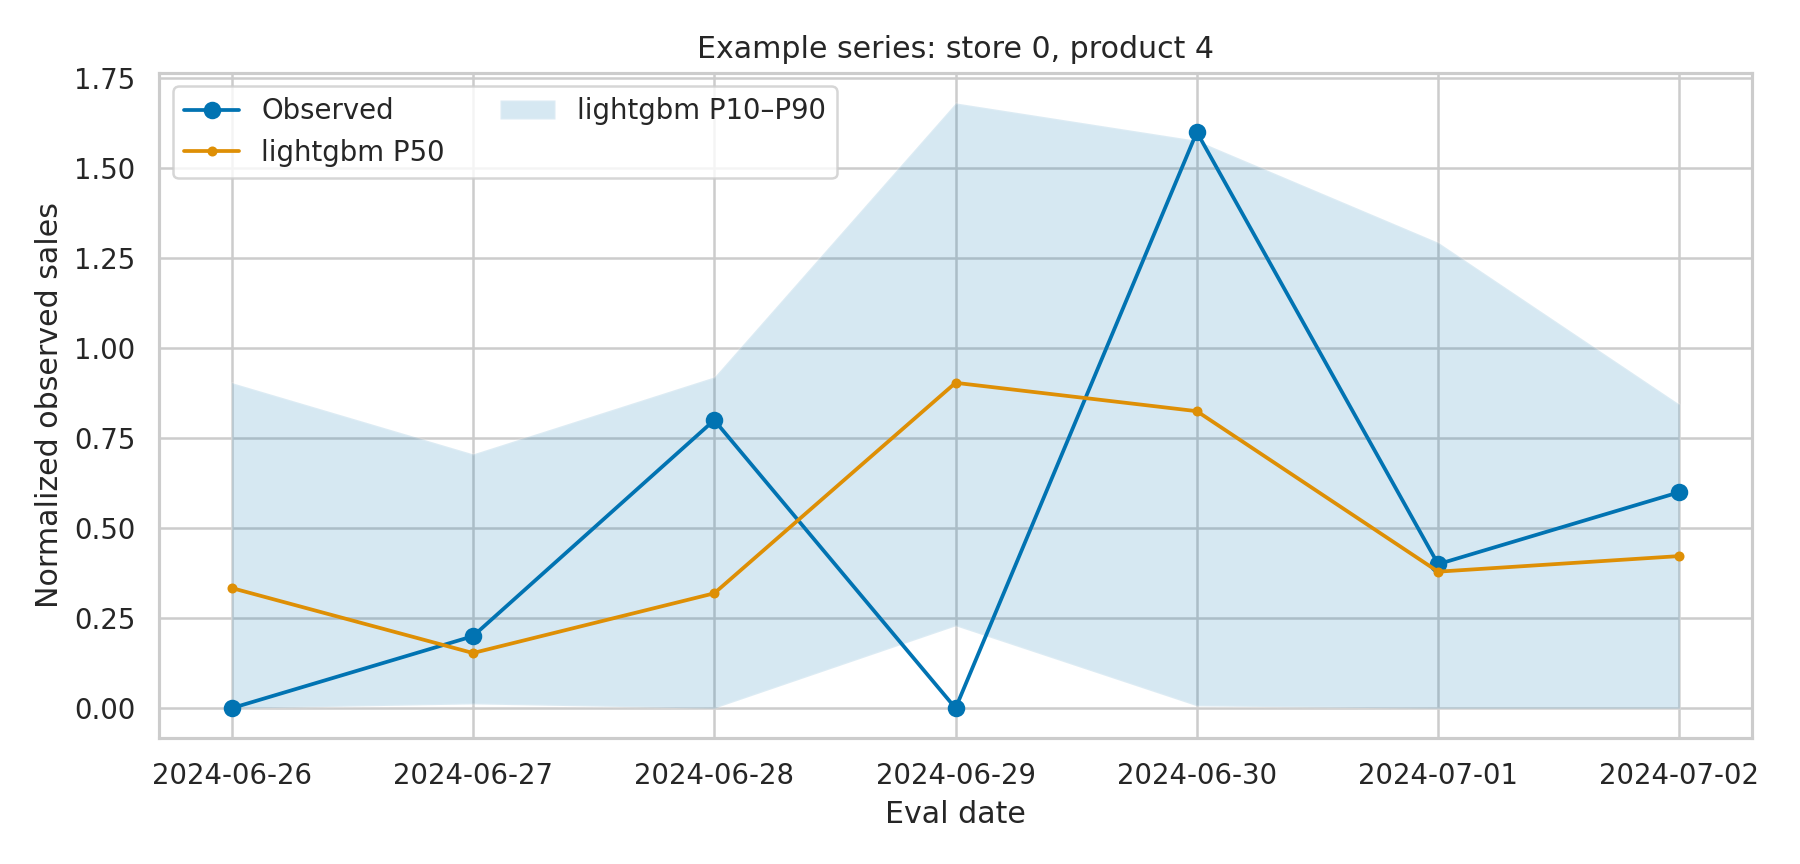

In [13]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Chuyển về thư mục dự án nếu Colab đang ở /content.
project = Path('/content/FreshRetailNet50K_Individual_Package')
if project.exists():
    os.chdir(project)

pred_path = Path('results/full_dataset_lightgbm/predictions_lightgbm.csv')
fig_path = Path('results/full_dataset_lightgbm/figures/06_example_forecast.png')

if not pred_path.is_file():
    print(f'Chưa tìm thấy {pred_path}. Hãy chạy ô LightGBM toàn bộ dữ liệu phía trên trước.')
else:
    pred = pd.read_csv(pred_path, parse_dates=['dt'])
    required = {'store_id', 'product_id', 'dt', 'sale_amount', 'q0.1', 'q0.5', 'q0.9'}
    missing = required.difference(pred.columns)
    if missing:
        raise ValueError(f'Tệp dự báo thiếu cột: {sorted(missing)}')

    # Chọn chuỗi có nhiều ngày dự báo nhất, tối đa bảy ngày eval.
    counts = pred.groupby(['store_id', 'product_id'], sort=True).size()
    max_n = counts.max()
    key = sorted([k for k, n in counts.items() if n == max_n])[0]
    example = pred[
        (pred['store_id'] == key[0]) & (pred['product_id'] == key[1])
    ].sort_values('dt')

    fig_path.parent.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(example['dt'], example['sale_amount'], marker='o', label='Observed')
    ax.plot(example['dt'], example['q0.5'], marker='.', label='lightgbm P50')
    ax.fill_between(
        example['dt'], example['q0.1'], example['q0.9'],
        alpha=0.16, label='lightgbm P10–P90'
    )
    ax.set(
        title=f'Example series: store {key[0]}, product {key[1]}',
        xlabel='Eval date',
        ylabel='Normalized observed sales',
    )
    ax.legend(ncol=2)
    fig.tight_layout()
    fig.savefig(fig_path, dpi=180)
    plt.close(fig)

    print(f'Đã tạo Hình 4.5: {fig_path} ({len(example)} ngày eval)')
    display(Image(filename=str(fig_path)))


## 5. So sánh ba mô hình trên panel chung 100 chuỗi

LightGBM, TFT và Chronos được huấn luyện/chạy suy luận lại trên cùng 100 chuỗi, được chọn bằng seed 17. Bảng so sánh chỉ sử dụng các quan sát có dự báo từ cả ba mô hình. Mỗi lần chạy sinh ra một bộ kết quả mới; cập nhật Word theo đúng các CSV và manifest của lượt chạy cuối.


In [14]:
COMPARE_MAX_SERIES = 100
SEED = 17
MODELS = 'lightgbm tft chronos'
!python src/run_experiment.py --max-series {COMPARE_MAX_SERIES} --seed {SEED} --models {MODELS} --results-dir results



Fitting lightgbm on 9,000 train rows; scoring 700 official eval rows
lightgbm: 700 predictions; 3.4s

Fitting tft on 9,000 train rows; scoring 700 official eval rows
Seed set to 17
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Light

## 6. Bảng kết quả mô hình

In [15]:
from pathlib import Path
import json, platform, importlib.metadata as md
import torch

packages = ['numpy','pandas','pyarrow','lightgbm','scikit-learn','lightning','pytorch-forecasting','chronos-forecasting','transformers','accelerate']
versions = {}
for package in packages:
    try: versions[package] = md.version(package)
    except md.PackageNotFoundError: versions[package] = None
runtime = {
    'python': platform.python_version(),
    'platform': platform.platform(),
    'package_versions': versions,
    'torch': torch.__version__,
    'cuda_runtime': torch.version.cuda,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'seed': 17,
    'chronos_sampling_seed': 'seed + batch_start',
    'chronos_model_revision': 'da0eb423156e8761c8540ccdbad501f38bc46142',
    'tft_trainer_deterministic': True,
}
for manifest_path in [Path('results/run_manifest.json'), Path('results/full_dataset_lightgbm/run_manifest.json')]:
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
        manifest['reproducibility_environment'] = runtime
        manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
        print('Manifest updated:', manifest_path)

for filename in ['metrics_overall.csv','metrics_by_stockout.csv','metrics_by_date.csv']:
    pth=Path('results')/filename
    print('###', filename)
    display(pd.read_csv(pth).round(5))


Manifest updated: results/run_manifest.json
Manifest updated: results/full_dataset_lightgbm/run_manifest.json
### metrics_overall.csv


,model,n,mae_p50,rmse_p50,wape_p50,pinball_p10,pinball_p50,pinball_p90,mean_pinball,coverage_80,mean_width_80,underprediction_rate_p50,bias_p50_actual_minus_forecast
0,lightgbm,700,0.36798,0.64879,0.32213,0.08039,0.18399,0.10007,0.12149,0.67143,0.94616,0.50714,0.07938
1,tft,700,0.42751,0.72432,0.37425,0.07890,0.21376,0.13776,0.14347,0.68429,0.96045,0.62429,0.22404
2,chronos,700,0.38110,0.63340,0.33361,0.07879,0.19055,0.11026,0.12653,0.70286,0.97094,0.54143,0.10479


### metrics_by_stockout.csv


,stockout_status,model,n,mae_p50,rmse_p50,wape_p50,pinball_p10,pinball_p50,pinball_p90,mean_pinball,coverage_80,mean_width_80,underprediction_rate_p50,bias_p50_actual_minus_forecast
0,No stockout recorded,lightgbm,453,0.35034,0.63115,0.30489,0.07286,0.17517,0.09705,0.11503,0.70640,0.96001,0.47461,0.08498
1,Stockout recorded,lightgbm,247,0.40034,0.67994,0.35429,0.09421,0.20017,0.10561,0.13333,0.60729,0.92076,0.56680,0.06909
2,No stockout recorded,tft,453,0.42291,0.74129,0.36804,0.07609,0.21145,0.14023,0.14259,0.70640,0.97342,0.61810,0.24565
3,Stockout recorded,tft,247,0.43596,0.69212,0.38582,0.08406,0.21798,0.13323,0.14509,0.64372,0.93666,0.63563,0.18441
4,No stockout recorded,chronos,453,0.36715,0.62017,0.31952,0.07144,0.18357,0.10792,0.12098,0.71965,0.97976,0.51435,0.11502
5,Stockout recorded,chronos,247,0.40668,0.65695,0.35991,0.09226,0.20334,0.11455,0.13672,0.67206,0.95476,0.59109,0.08602


### metrics_by_date.csv


,dt,model,n,mae_p50,rmse_p50,wape_p50,pinball_p10,pinball_p50,pinball_p90,mean_pinball,coverage_80,mean_width_80,underprediction_rate_p50,bias_p50_actual_minus_forecast
0,2024-06-26,lightgbm,100,0.29595,0.43221,0.27925,0.06090,0.14797,0.07944,0.09610,0.76,0.88535,0.52,0.02798
1,2024-06-27,lightgbm,100,0.30875,0.47133,0.28580,0.06167,0.15437,0.10041,0.10549,0.67,0.87146,0.45,0.05718
2,2024-06-28,lightgbm,100,0.28443,0.42491,0.29024,0.06213,0.14222,0.07149,0.09195,0.74,0.90290,0.44,-0.02550
3,2024-06-29,lightgbm,100,0.46602,0.88641,0.34128,0.09729,0.23301,0.12070,0.15033,0.66,1.10244,0.49,0.20138
4,2024-06-30,lightgbm,100,0.49134,0.93896,0.34819,0.10682,0.24567,0.14577,0.16609,0.59,1.07661,0.67,0.22233
5,2024-07-01,lightgbm,100,0.36223,0.56035,0.35066,0.08459,0.18112,0.09237,0.11936,0.64,0.89691,0.44,0.00604
6,2024-07-02,lightgbm,100,0.36716,0.61286,0.34424,0.08934,0.18358,0.09032,0.12108,0.64,0.88745,0.54,0.06623
7,2024-06-26,tft,100,0.32640,0.46770,0.30799,0.06155,0.16320,0.09328,0.10601,0.75,0.93197,0.66,0.16160
8,2024-06-27,tft,100,0.38196,0.58850,0.35357,0.06817,0.19098,0.13892,0.13269,0.66,0.86991,0.65,0.27525
9,2024-06-28,tft,100,0.35026,0.51694,0.35741,0.06572,0.17513,0.08769,0.10951,0.74,0.90972,0.61,0.12723


## 7. Kiểm tra chất lượng khoảng dự báo và biểu đồ mô hình

## LightGBM 50.000 chuỗi
01_training_sales_trend.png


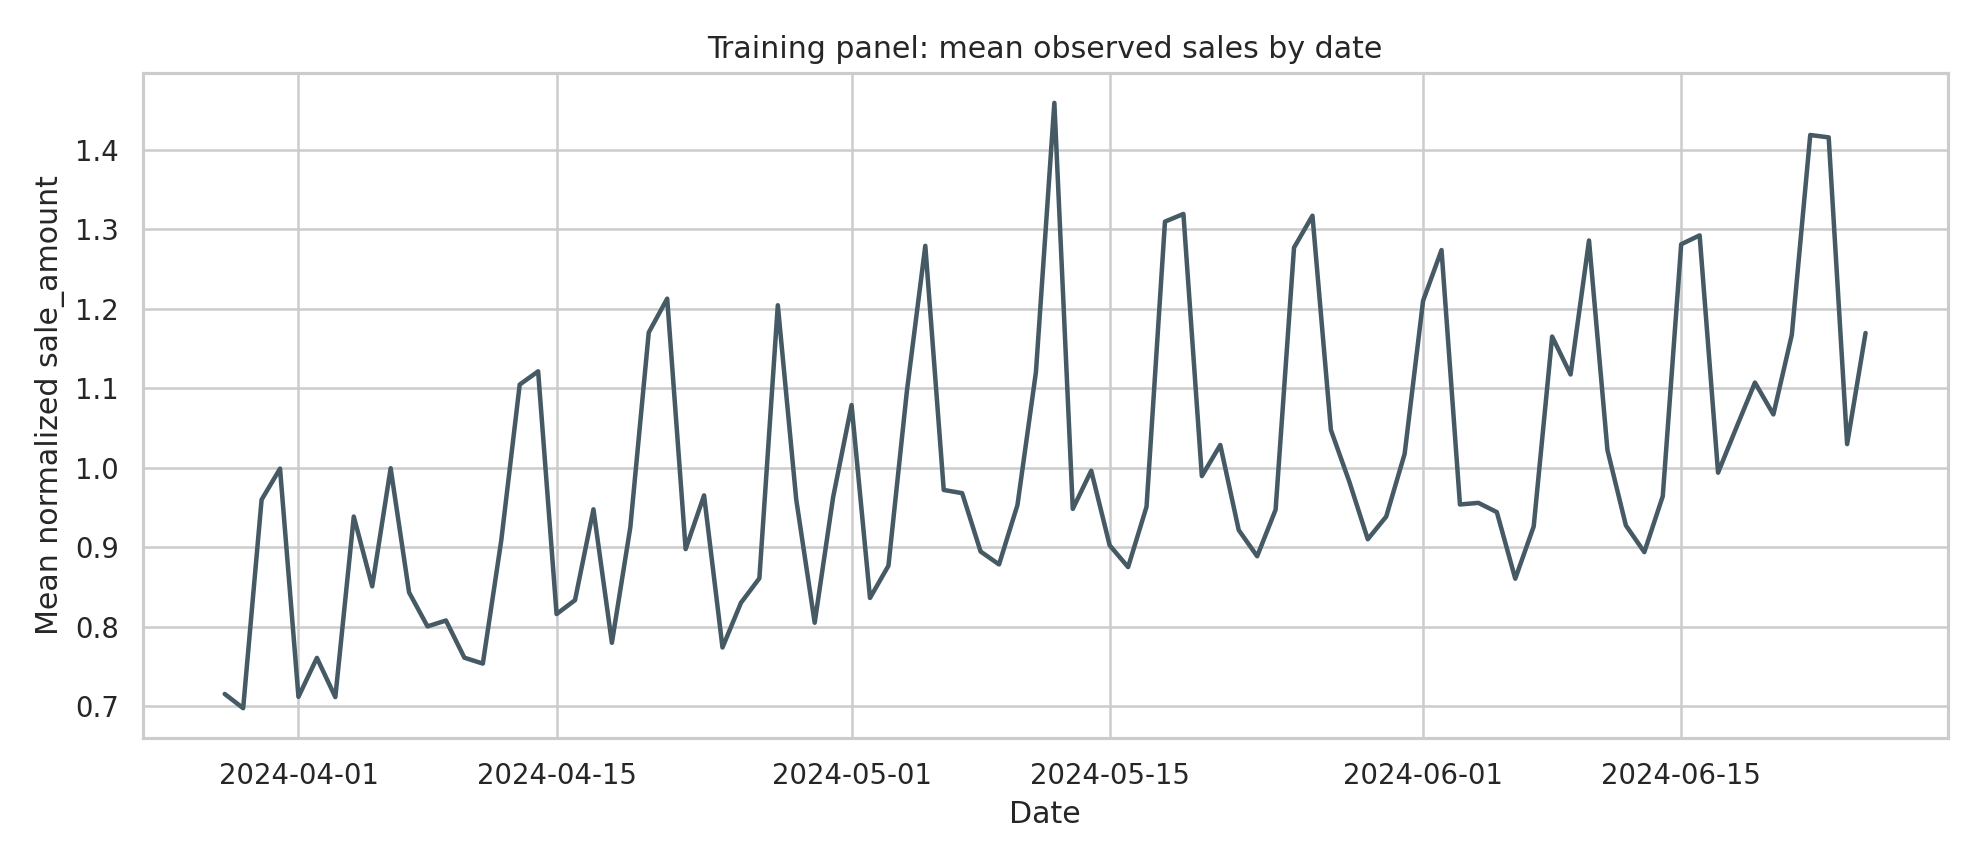

02_model_error_comparison.png


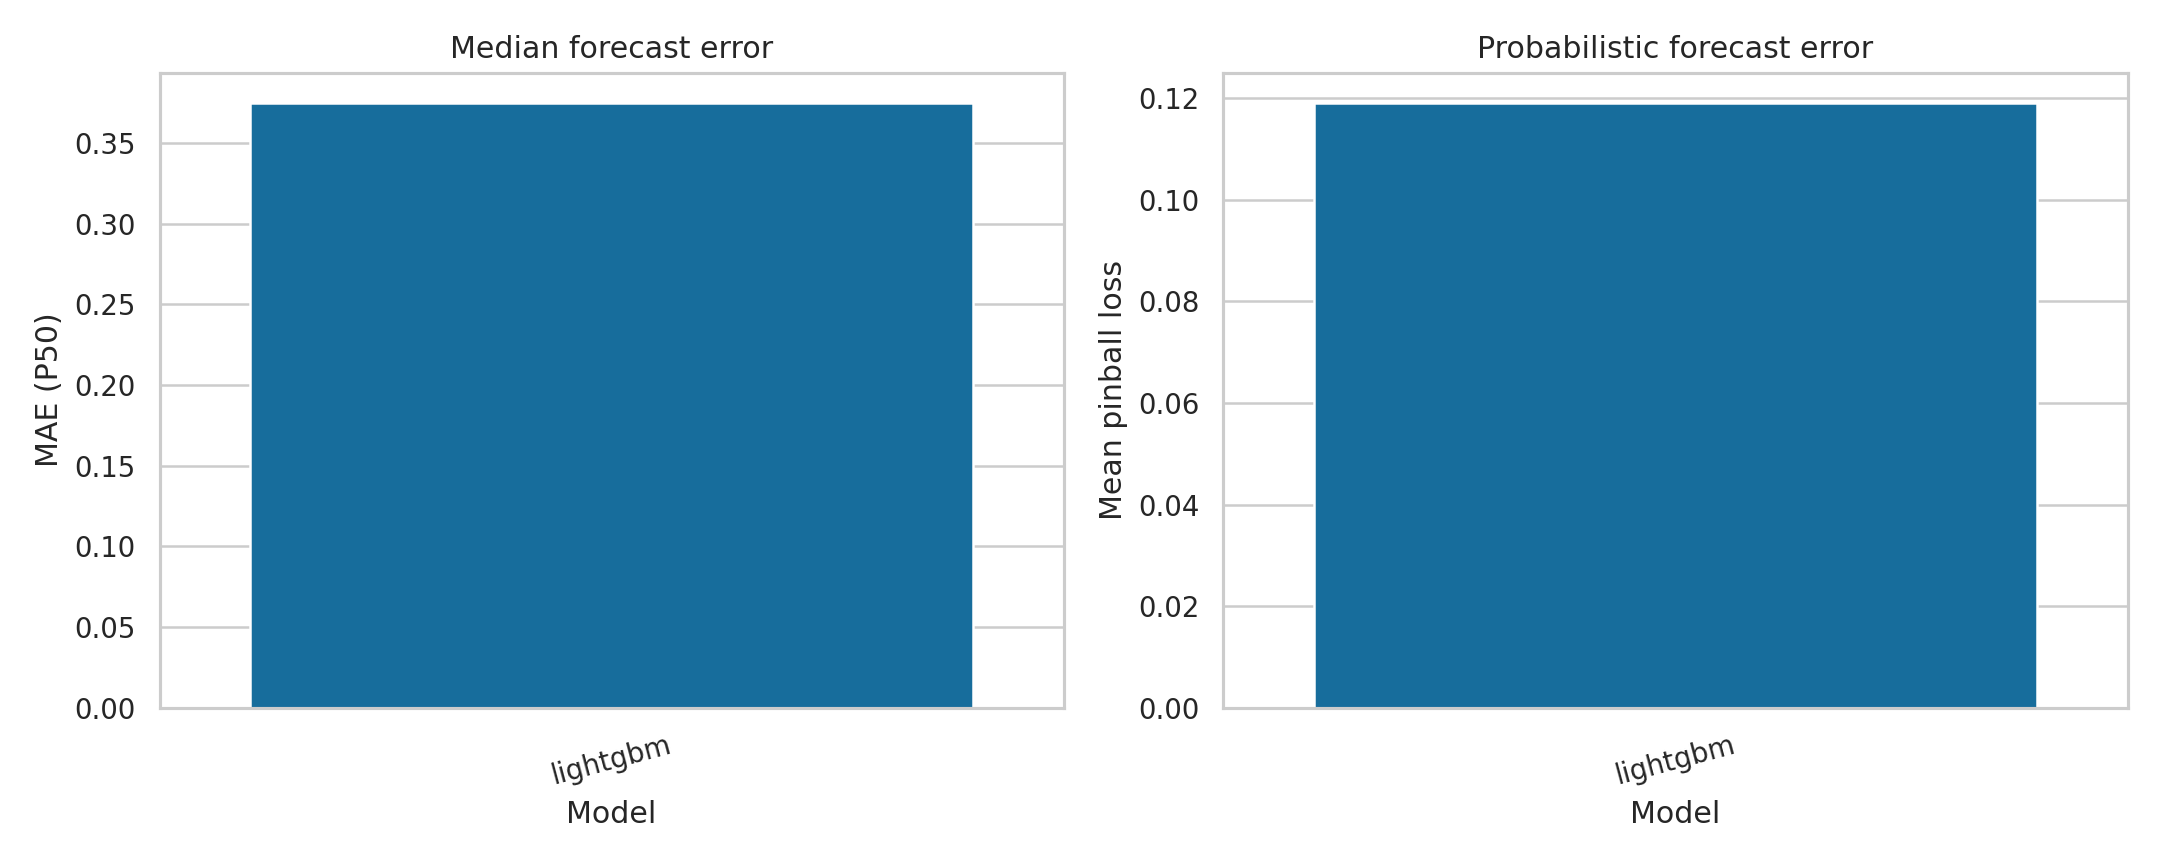

03_interval_diagnostics.png


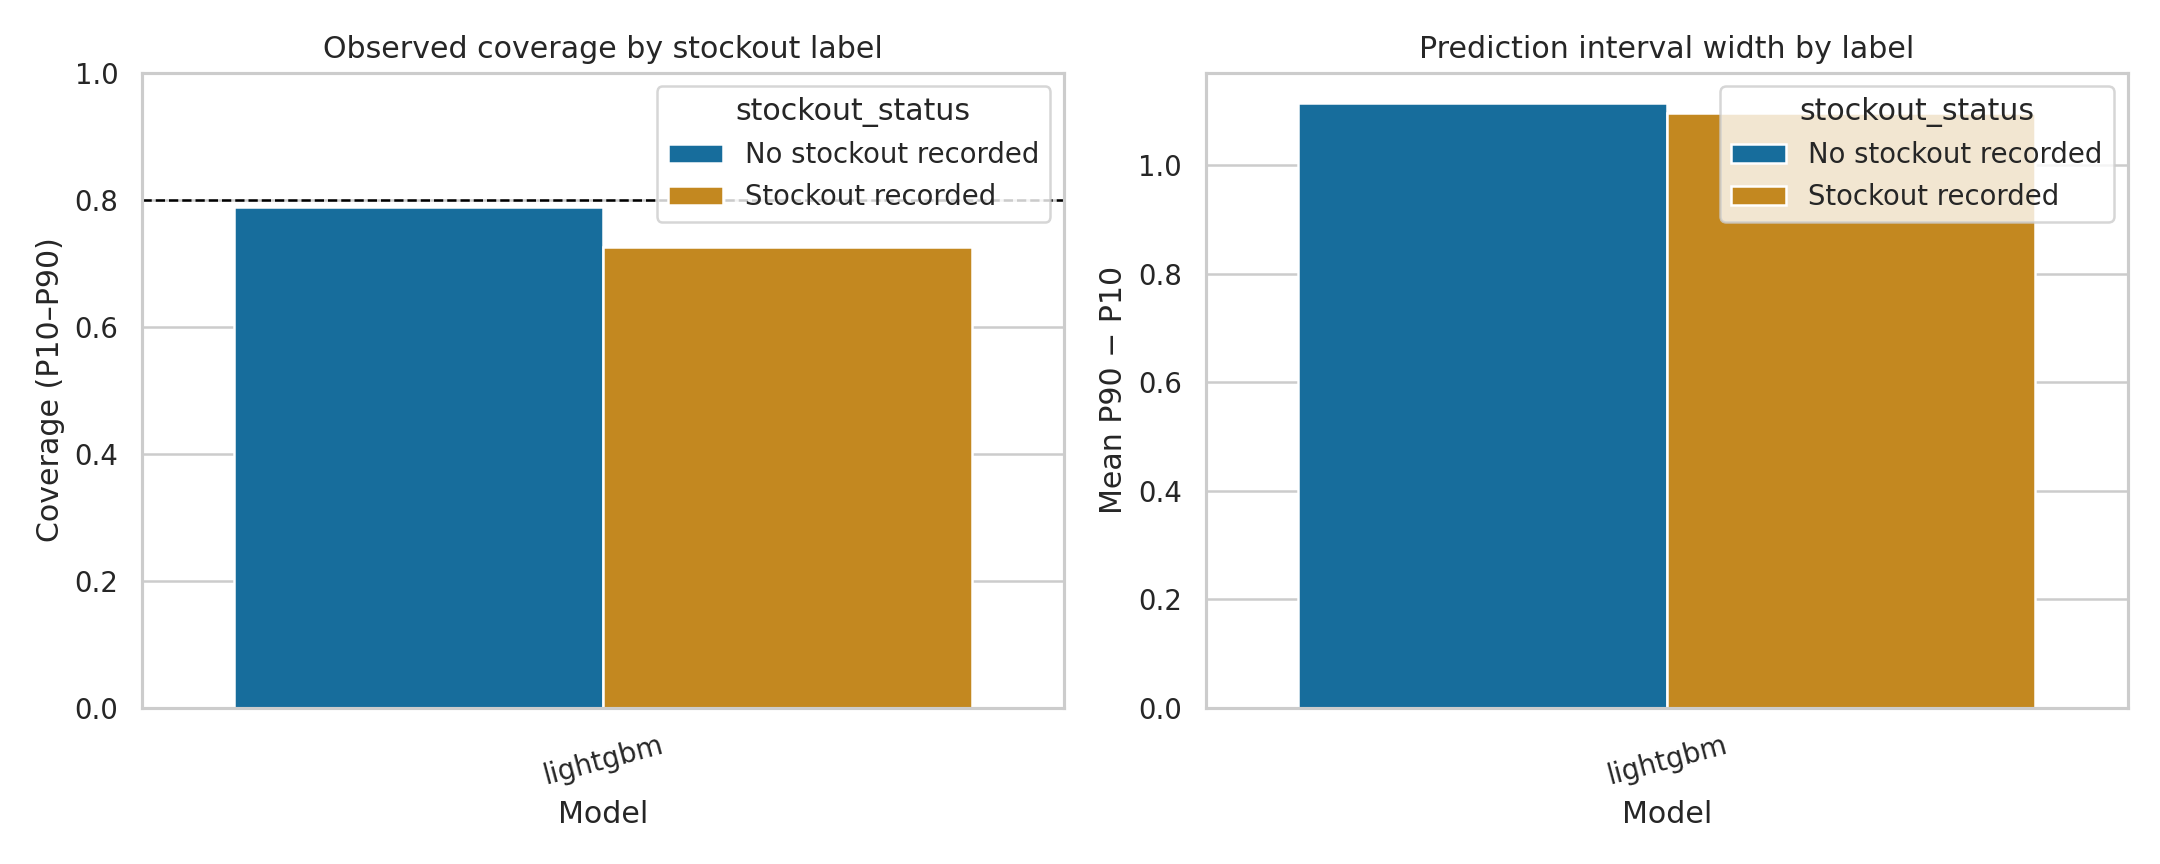

04_residuals_by_stockout.png


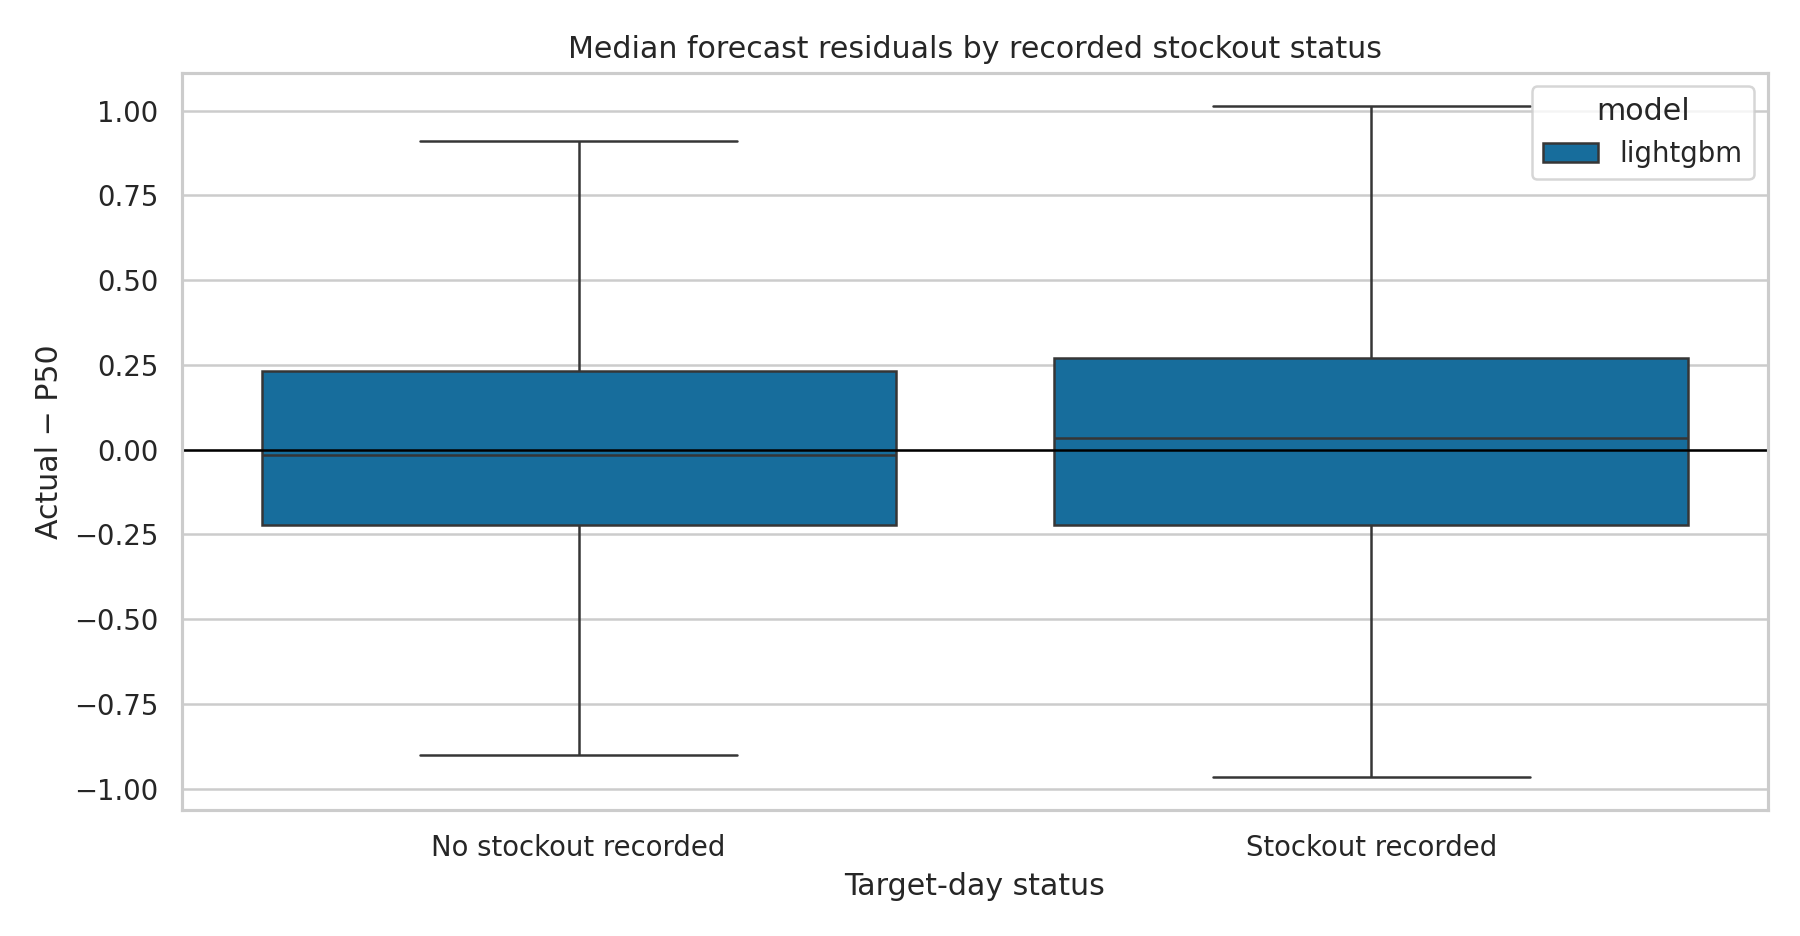

05_actual_vs_median.png


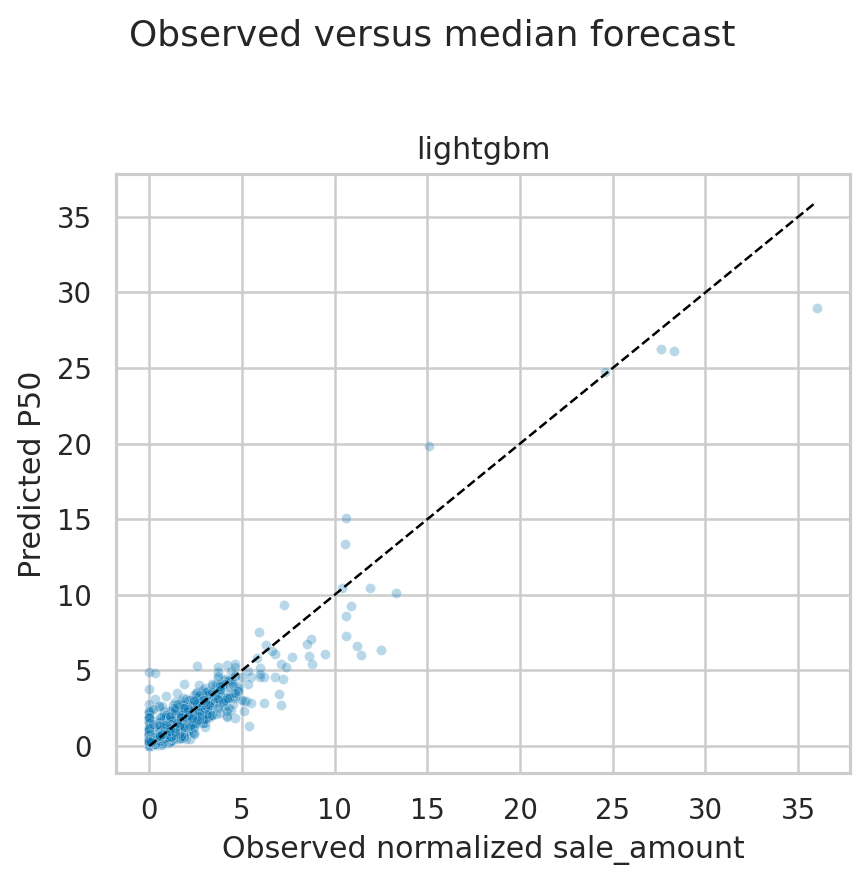

06_example_forecast.png


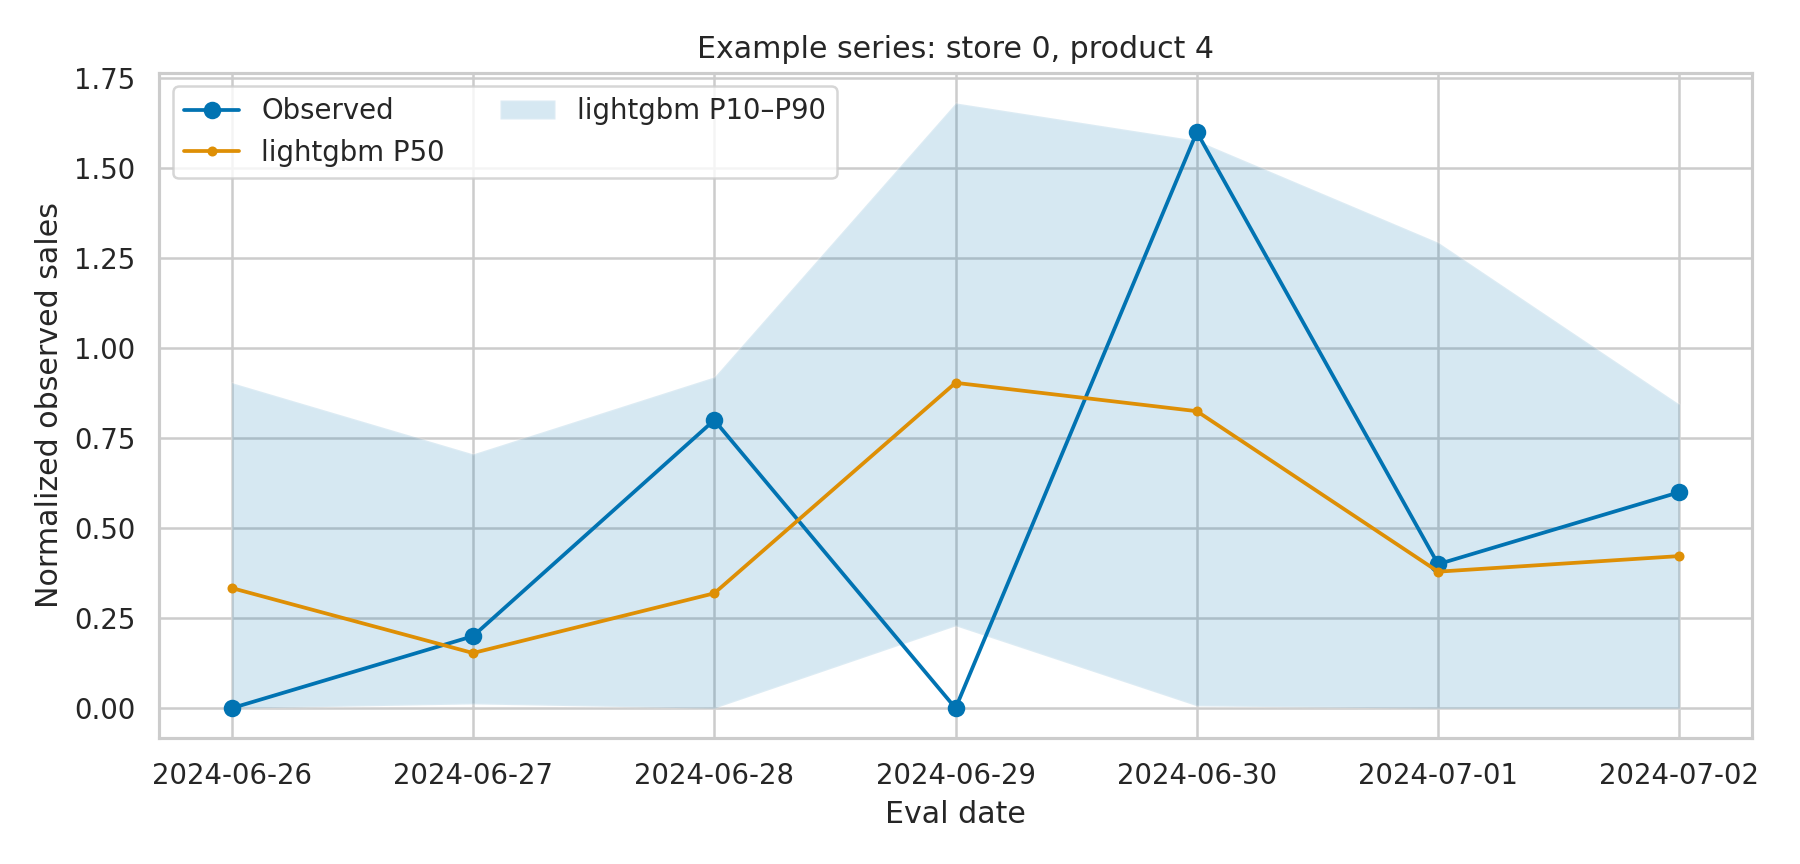

## So sánh 100 chuỗi
01_training_sales_trend.png


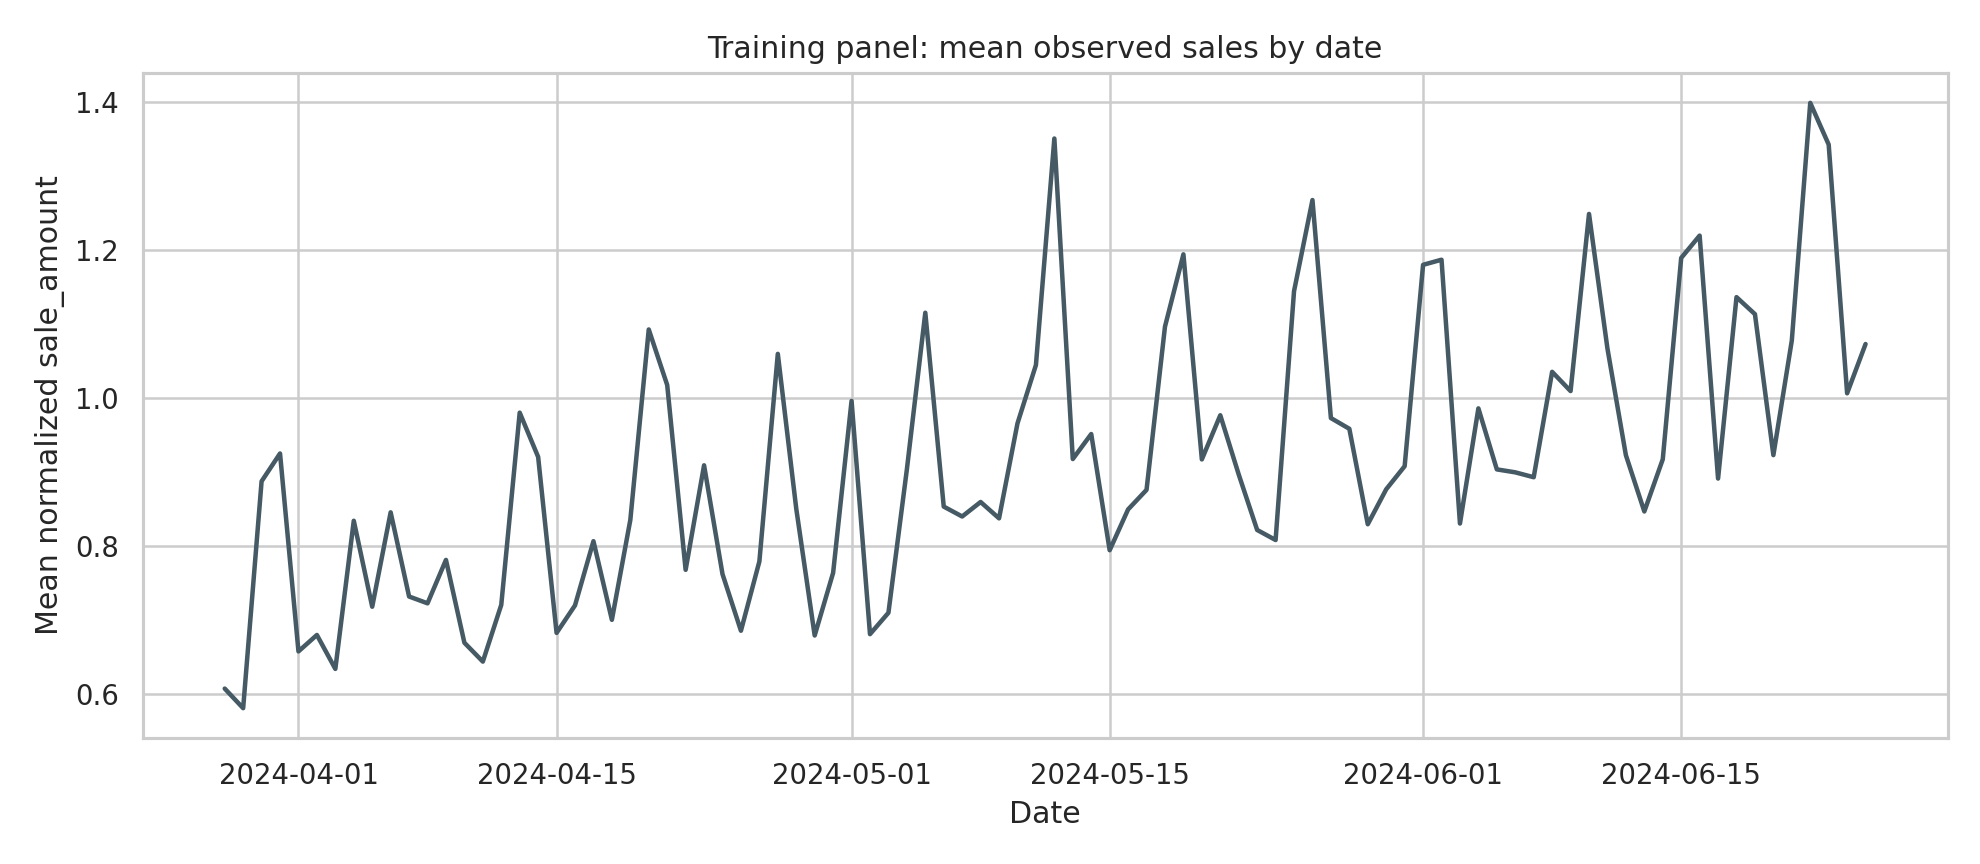

02_model_error_comparison.png


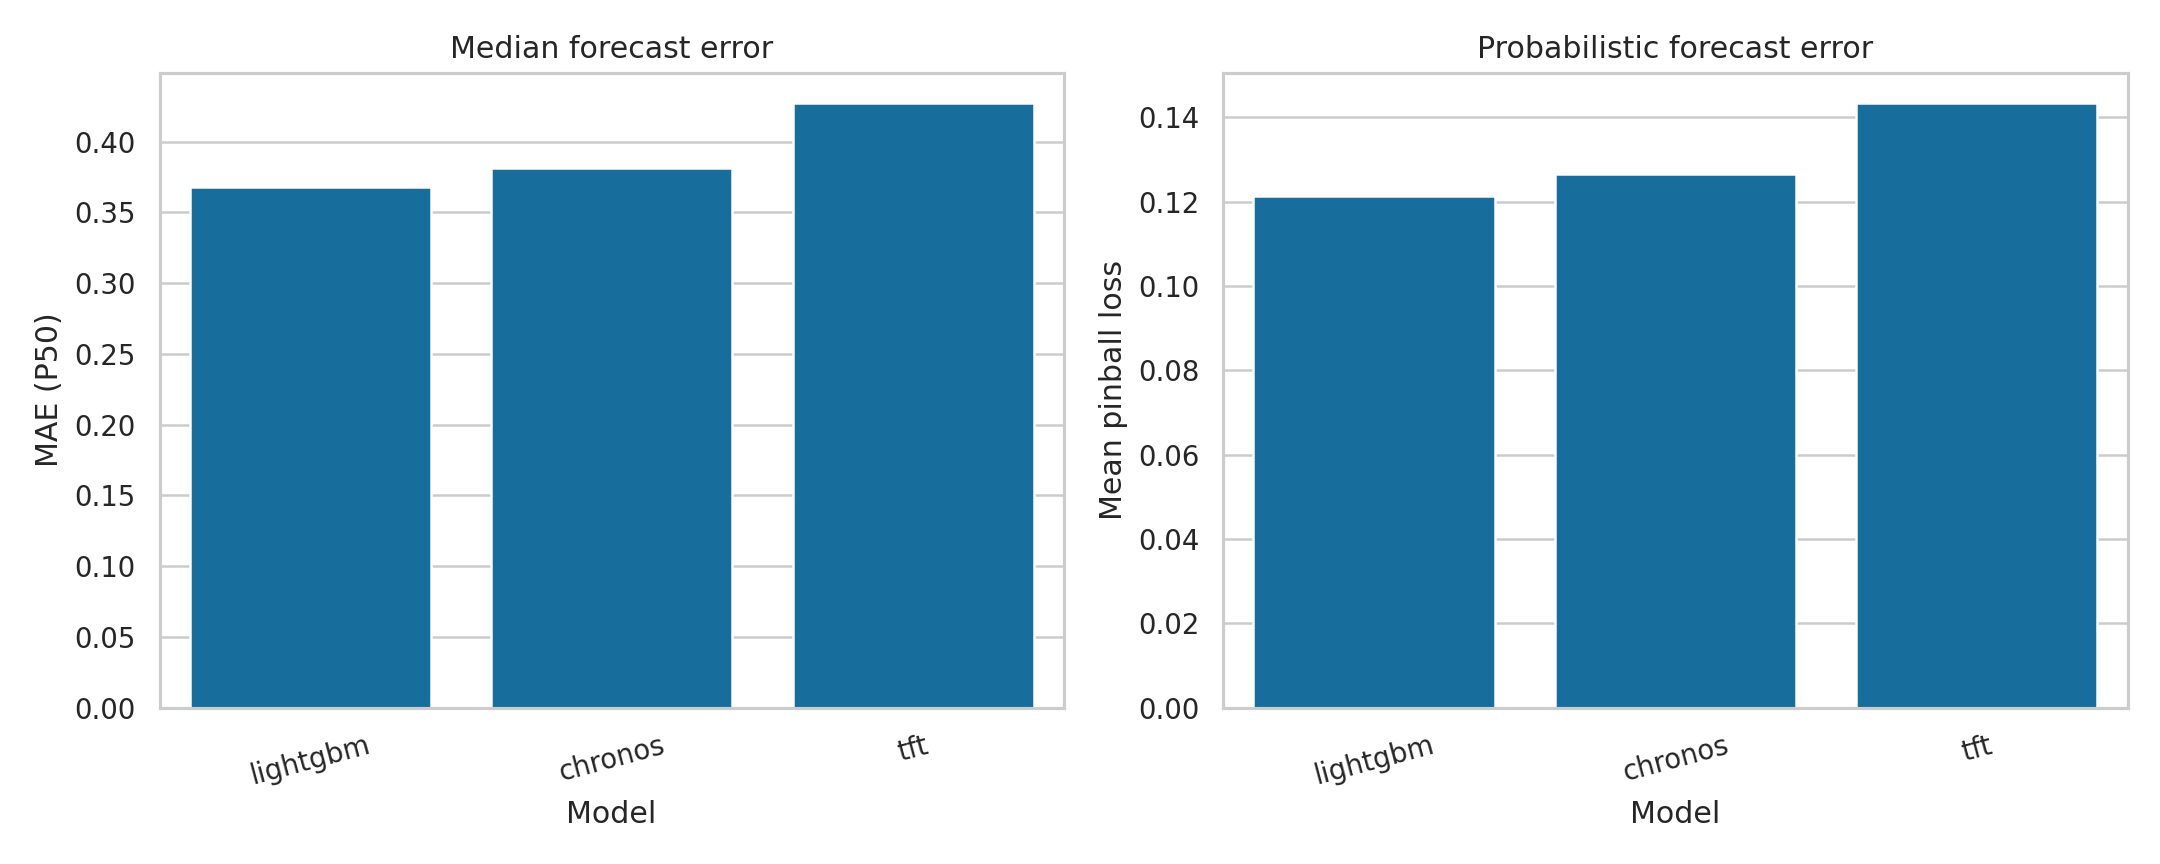

03_interval_diagnostics.png


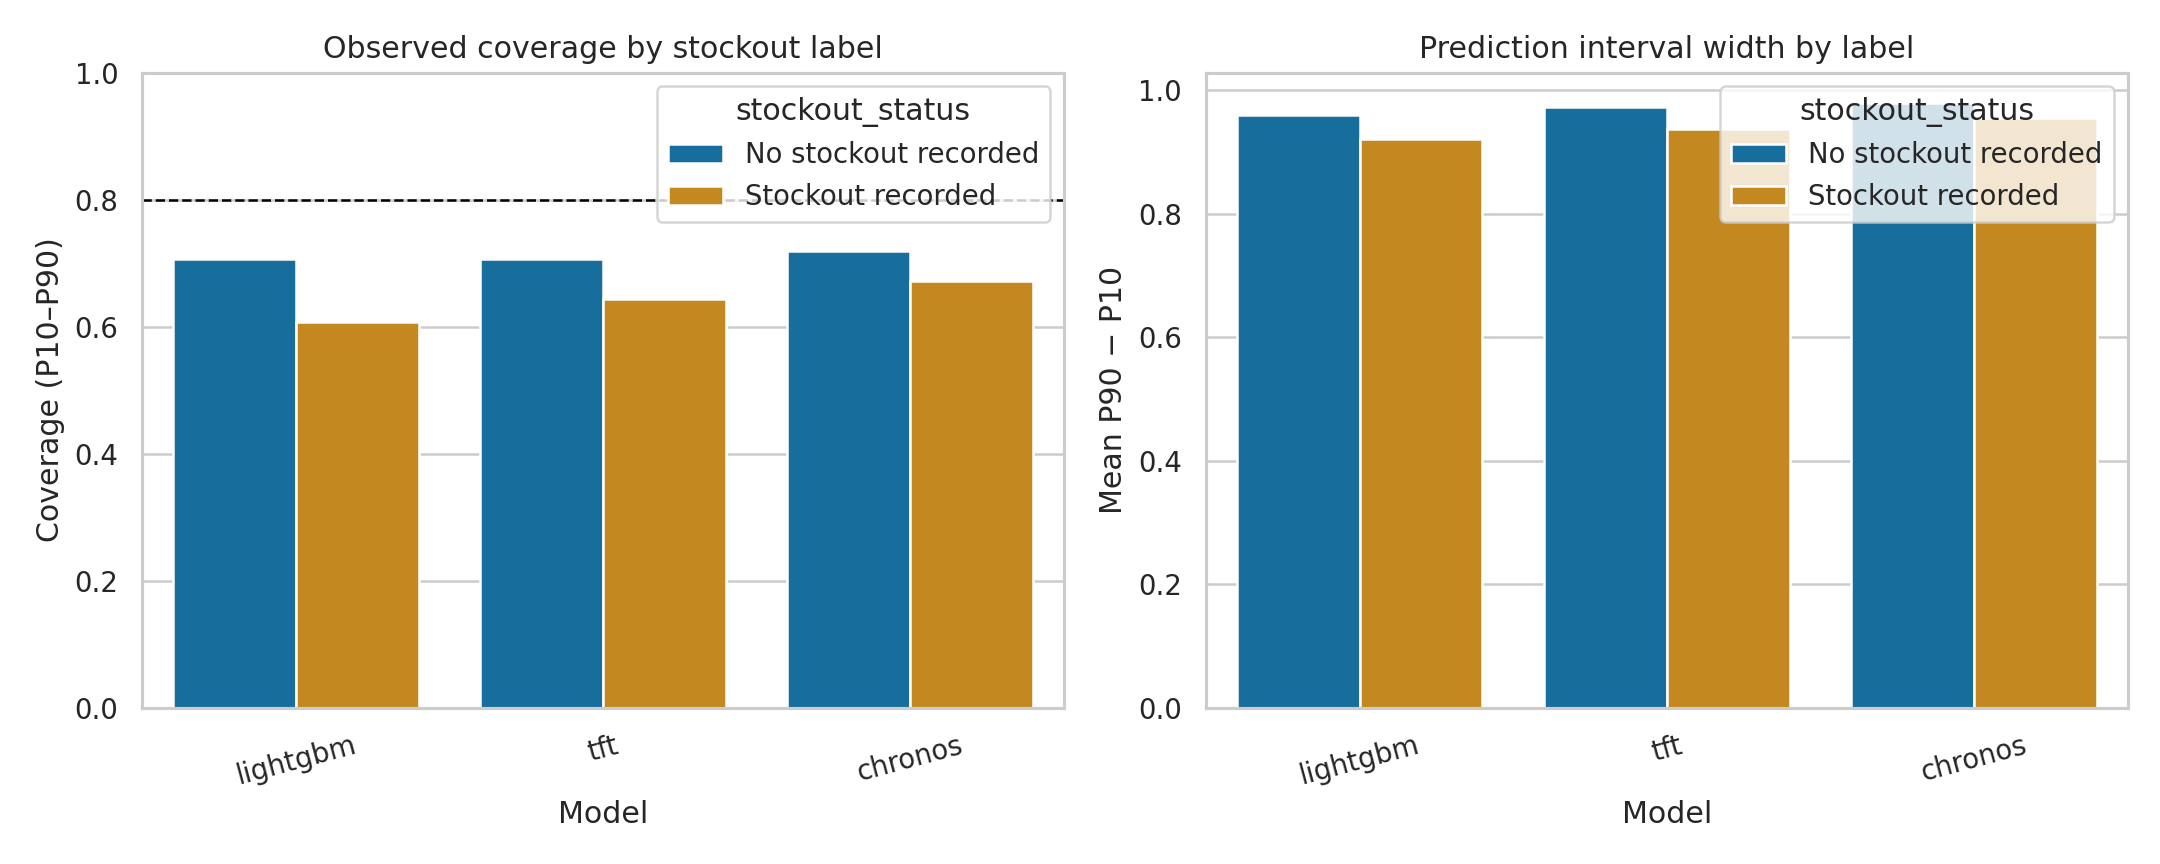

04_residuals_by_stockout.png


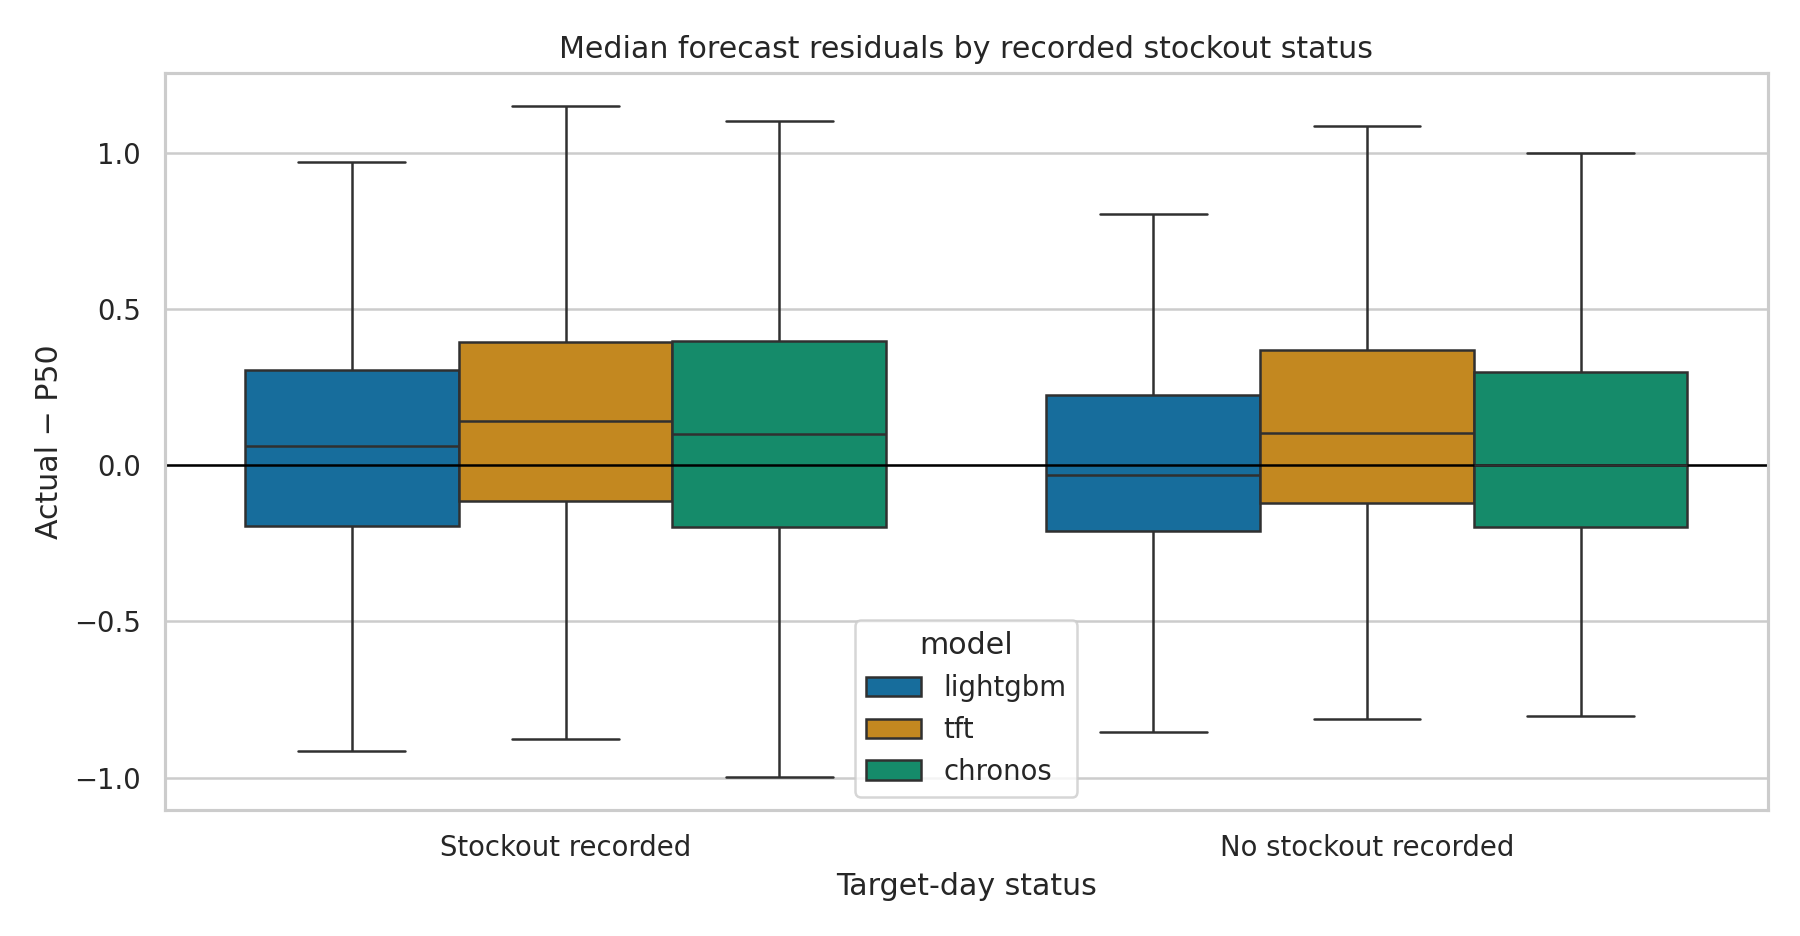

05_actual_vs_median.png


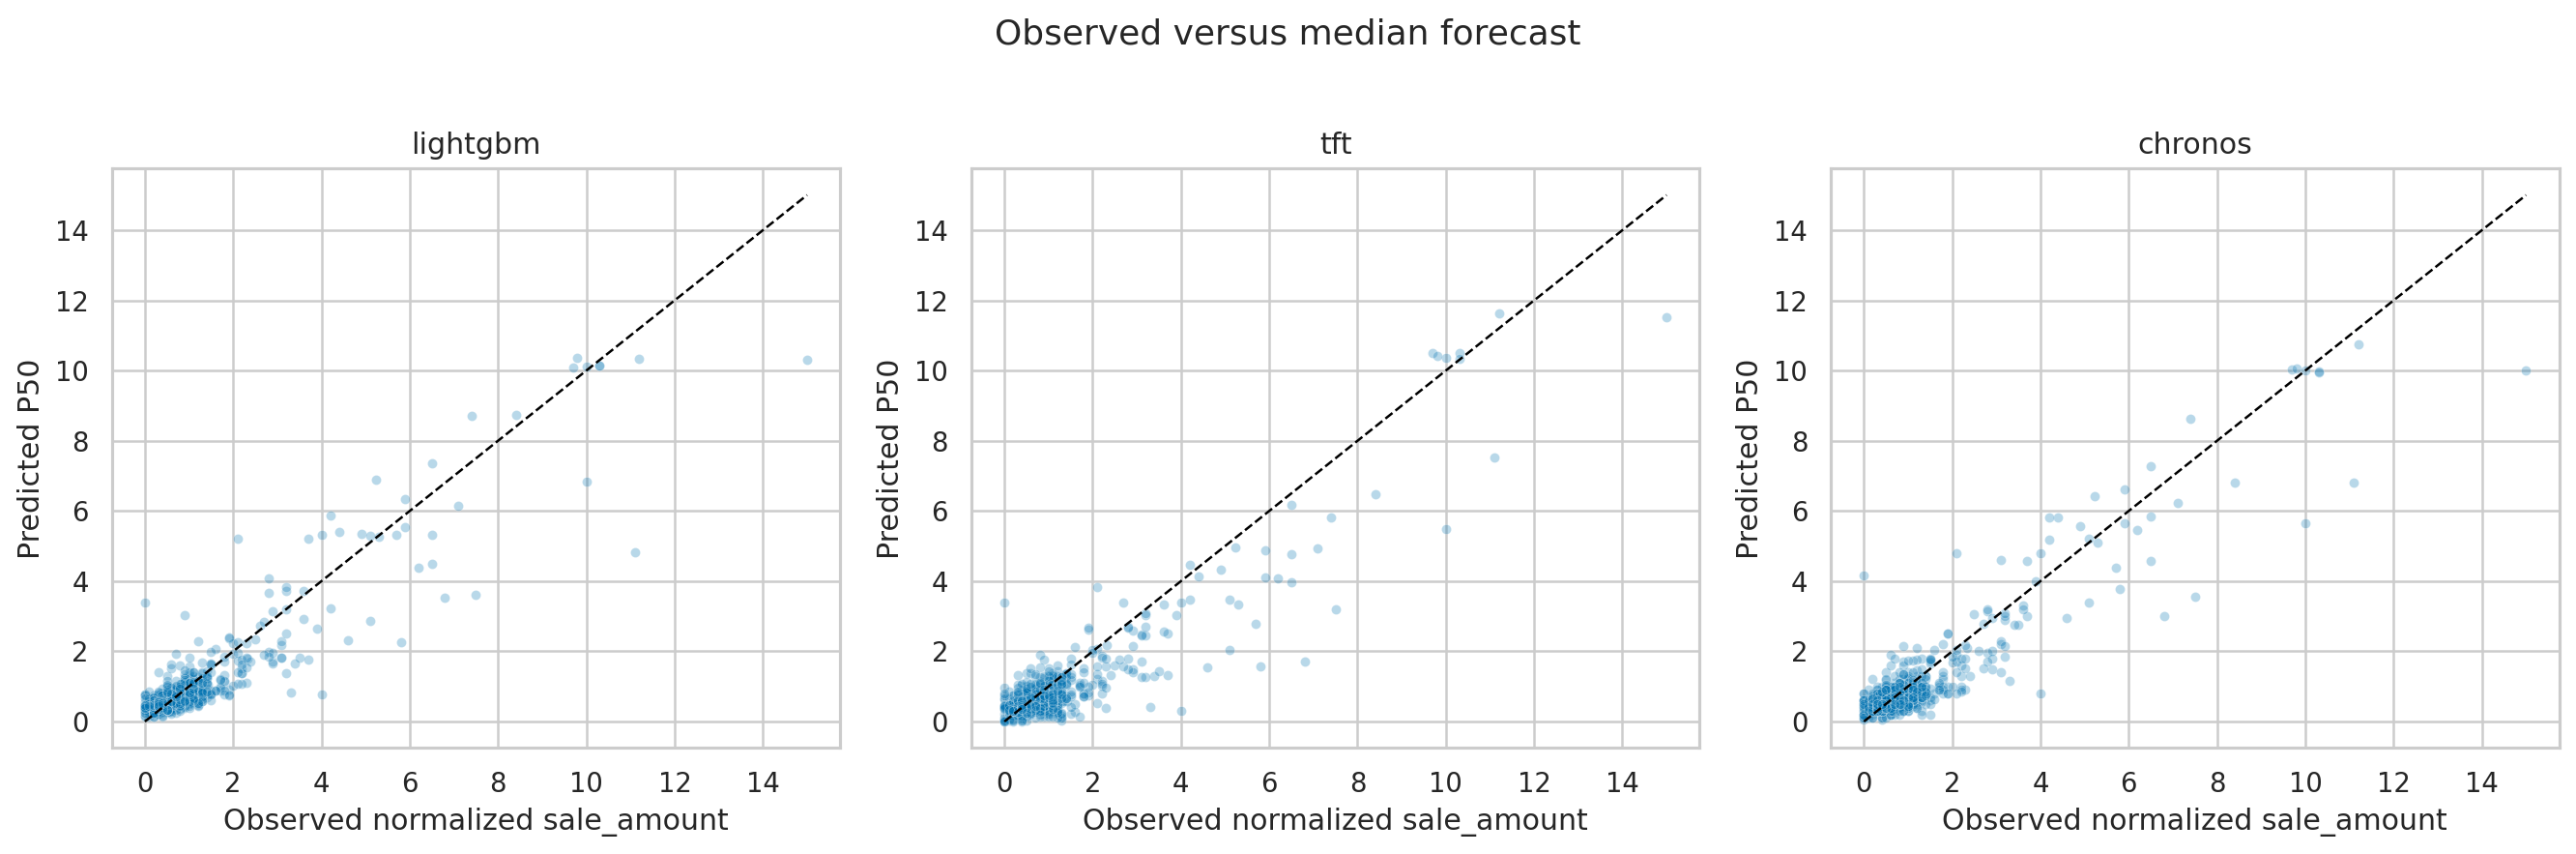

06_example_forecast.png


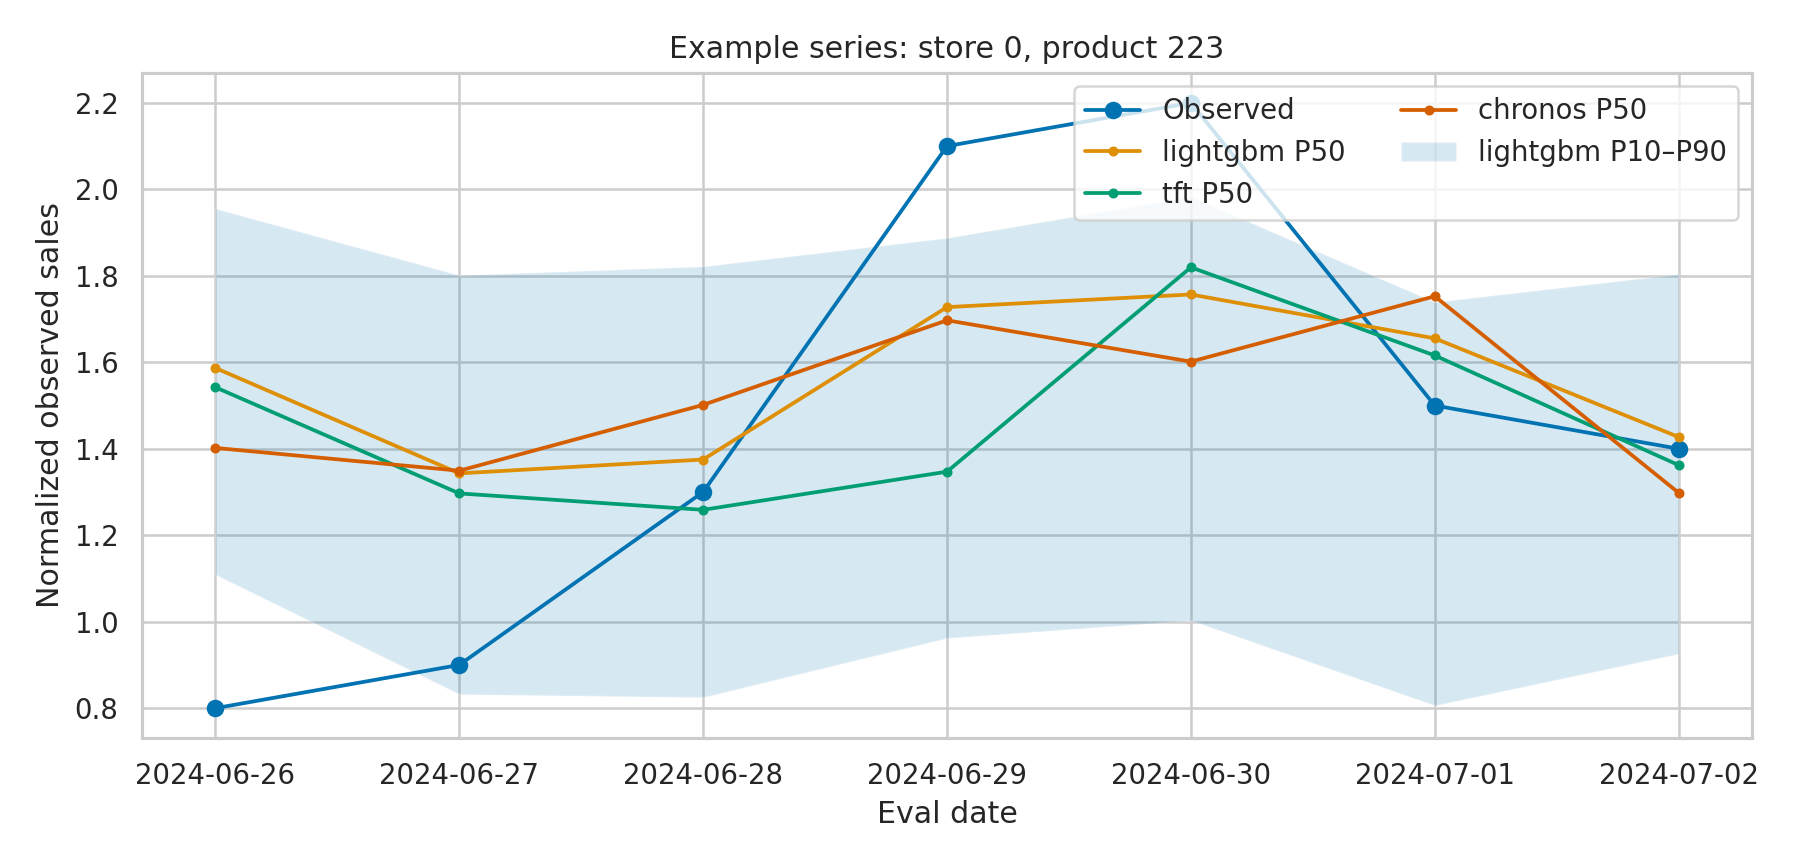

In [16]:
for label, folder in [('LightGBM 50.000 chuỗi', Path('results/full_dataset_lightgbm/figures')), ('So sánh 100 chuỗi', Path('results/figures'))]:
    print('##', label)
    for pth in sorted(folder.glob('*.png')):
        print(pth.name); display(Image(filename=str(pth)))


### 7.1. Phân tích tự động

In [17]:
report_path = Path('results/analysis_report.md')
if report_path.exists(): display(Markdown(report_path.read_text()))
manifest = json.loads(Path('results/run_manifest.json').read_text())
print('Manifest của lượt chạy mới:', json.dumps(manifest,ensure_ascii=False,indent=2))


# FreshRetailNet-50K experiment report

## Executive summary

This report was generated from the files and predictions produced by the current run. It compares one-day-ahead P10/P50/P90 forecasts of the dataset's normalized `sale_amount`. It does not estimate latent demand.

Lowest P50 MAE: lightgbm (0.367982; n=700).

Lowest mean pinball loss across P10/P50/P90: lightgbm (0.121486).

chronos: P50 MAE difference (stockout minus no stockout) = 0.0395318; interpret descriptively because status is observational and group sizes may differ.

lightgbm: P50 MAE difference (stockout minus no stockout) = 0.0499982; interpret descriptively because status is observational and group sizes may differ.

tft: P50 MAE difference (stockout minus no stockout) = 0.0130523; interpret descriptively because status is observational and group sizes may differ.

Coverage closest to nominal 80%: chronos (70.3%). Coverage is an empirical calibration check, not a guarantee for future periods.

Comparisons are descriptive. They do not establish that stockouts cause the error difference, and the target remains normalized observed sales rather than latent demand.

## Evaluation protocol

- Official train dates: 2024-03-28 to 2024-06-25
- Official eval dates: 2024-06-26 to 2024-07-02
- Selected real store-product series: 100
- Train rows used: 9,000; eval rows scored: 700
- Evaluation is rolling one-day-ahead: previous observed days are available as history, including earlier eval days, but the target day's sale is excluded from its own features/context.
- Stockout status is attached after forecasts are generated and used only to stratify error summaries.

## Overall metrics

| model    |   n |   mae_p50 |   rmse_p50 |   wape_p50 |   pinball_p10 |   pinball_p50 |   pinball_p90 |   mean_pinball |   coverage_80 |   mean_width_80 |   underprediction_rate_p50 |   bias_p50_actual_minus_forecast |
|:---------|----:|----------:|-----------:|-----------:|--------------:|--------------:|--------------:|---------------:|--------------:|----------------:|---------------------------:|---------------------------------:|
| lightgbm | 700 |   0.36798 |    0.64879 |    0.32213 |       0.08039 |       0.18399 |       0.10007 |        0.12149 |       0.67143 |         0.94616 |                    0.50714 |                          0.07938 |
| tft      | 700 |   0.42751 |    0.72432 |    0.37425 |       0.07890 |       0.21376 |       0.13776 |        0.14347 |       0.68429 |         0.96045 |                    0.62429 |                          0.22404 |
| chronos  | 700 |   0.38110 |    0.63340 |    0.33361 |       0.07879 |       0.19055 |       0.11026 |        0.12653 |       0.70286 |         0.97094 |                    0.54143 |                          0.10479 |

`coverage_80` is the empirical share of actuals between P10 and P90. The nominal target is 0.80. `mean_width_80` measures average interval width. Lower error metrics are better; coverage is best interpreted together with interval width.

## Results by target-day stockout label

| stockout_status      | model    |   n |   mae_p50 |   rmse_p50 |   wape_p50 |   pinball_p10 |   pinball_p50 |   pinball_p90 |   mean_pinball |   coverage_80 |   mean_width_80 |   underprediction_rate_p50 |   bias_p50_actual_minus_forecast |
|:---------------------|:---------|----:|----------:|-----------:|-----------:|--------------:|--------------:|--------------:|---------------:|--------------:|----------------:|---------------------------:|---------------------------------:|
| No stockout recorded | lightgbm | 453 |   0.35034 |    0.63115 |    0.30489 |       0.07286 |       0.17517 |       0.09705 |        0.11503 |       0.70640 |         0.96001 |                    0.47461 |                          0.08498 |
| Stockout recorded    | lightgbm | 247 |   0.40034 |    0.67994 |    0.35429 |       0.09421 |       0.20017 |       0.10561 |        0.13333 |       0.60729 |         0.92076 |                    0.56680 |                          0.06909 |
| No stockout recorded | tft      | 453 |   0.42291 |    0.74129 |    0.36804 |       0.07609 |       0.21145 |       0.14023 |        0.14259 |       0.70640 |         0.97342 |                    0.61810 |                          0.24565 |
| Stockout recorded    | tft      | 247 |   0.43596 |    0.69212 |    0.38582 |       0.08406 |       0.21798 |       0.13323 |        0.14509 |       0.64372 |         0.93666 |                    0.63563 |                          0.18441 |
| No stockout recorded | chronos  | 453 |   0.36715 |    0.62017 |    0.31952 |       0.07144 |       0.18357 |       0.10792 |        0.12098 |       0.71965 |         0.97976 |                    0.51435 |                          0.11502 |
| Stockout recorded    | chronos  | 247 |   0.40668 |    0.65695 |    0.35991 |       0.09226 |       0.20334 |       0.11455 |        0.13672 |       0.67206 |         0.95476 |                    0.59109 |                          0.08602 |

The label `Stockout recorded` means `stock_hour6_22_cnt > 0`; it does not mean all lost demand is known. Subgroup differences are descriptive and may reflect product, store, day, or promotion mix.

## Metrics by evaluation date

| dt                  | model    |   n |   mae_p50 |   rmse_p50 |   wape_p50 |   pinball_p10 |   pinball_p50 |   pinball_p90 |   mean_pinball |   coverage_80 |   mean_width_80 |   underprediction_rate_p50 |   bias_p50_actual_minus_forecast |
|:--------------------|:---------|----:|----------:|-----------:|-----------:|--------------:|--------------:|--------------:|---------------:|--------------:|----------------:|---------------------------:|---------------------------------:|
| 2024-06-26 00:00:00 | lightgbm | 100 |   0.29595 |    0.43221 |    0.27925 |       0.06090 |       0.14797 |       0.07944 |        0.09610 |       0.76000 |         0.88535 |                    0.52000 |                          0.02798 |
| 2024-06-27 00:00:00 | lightgbm | 100 |   0.30875 |    0.47133 |    0.28580 |       0.06167 |       0.15437 |       0.10041 |        0.10549 |       0.67000 |         0.87146 |                    0.45000 |                          0.05718 |
| 2024-06-28 00:00:00 | lightgbm | 100 |   0.28443 |    0.42491 |    0.29024 |       0.06213 |       0.14222 |       0.07149 |        0.09195 |       0.74000 |         0.90290 |                    0.44000 |                         -0.02550 |
| 2024-06-29 00:00:00 | lightgbm | 100 |   0.46602 |    0.88641 |    0.34128 |       0.09729 |       0.23301 |       0.12070 |        0.15033 |       0.66000 |         1.10244 |                    0.49000 |                          0.20138 |
| 2024-06-30 00:00:00 | lightgbm | 100 |   0.49134 |    0.93896 |    0.34819 |       0.10682 |       0.24567 |       0.14577 |        0.16609 |       0.59000 |         1.07661 |                    0.67000 |                          0.22233 |
| 2024-07-01 00:00:00 | lightgbm | 100 |   0.36223 |    0.56035 |    0.35066 |       0.08459 |       0.18112 |       0.09237 |        0.11936 |       0.64000 |         0.89691 |                    0.44000 |                          0.00604 |
| 2024-07-02 00:00:00 | lightgbm | 100 |   0.36716 |    0.61286 |    0.34424 |       0.08934 |       0.18358 |       0.09032 |        0.12108 |       0.64000 |         0.88745 |                    0.54000 |                          0.06623 |
| 2024-06-26 00:00:00 | tft      | 100 |   0.32640 |    0.46770 |    0.30799 |       0.06155 |       0.16320 |       0.09328 |        0.10601 |       0.75000 |         0.93197 |                    0.66000 |                          0.16160 |
| 2024-06-27 00:00:00 | tft      | 100 |   0.38196 |    0.58850 |    0.35357 |       0.06817 |       0.19098 |       0.13892 |        0.13269 |       0.66000 |         0.86991 |                    0.65000 |                          0.27525 |
| 2024-06-28 00:00:00 | tft      | 100 |   0.35026 |    0.51694 |    0.35741 |       0.06572 |       0.17513 |       0.08769 |        0.10951 |       0.74000 |         0.90972 |                    0.61000 |                          0.12723 |
| 2024-06-29 00:00:00 | tft      | 100 |   0.57340 |    1.06009 |    0.41992 |       0.09554 |       0.28670 |       0.22807 |        0.20344 |       0.59000 |         1.00951 |                    0.63000 |                          0.39254 |
| 2024-06-30 00:00:00 | tft      | 100 |   0.52139 |    0.81573 |    0.36949 |       0.09394 |       0.26069 |       0.16081 |        0.17181 |       0.66000 |         1.09377 |                    0.69000 |                          0.30887 |
| 2024-07-01 00:00:00 | tft      | 100 |   0.42281 |    0.73735 |    0.40930 |       0.07823 |       0.21140 |       0.14234 |        0.14399 |       0.70000 |         0.93782 |                    0.56000 |                          0.15471 |
| 2024-07-02 00:00:00 | tft      | 100 |   0.41638 |    0.71223 |    0.39038 |       0.08919 |       0.20819 |       0.11321 |        0.13686 |       0.69000 |         0.97047 |                    0.57000 |                          0.14809 |
| 2024-06-26 00:00:00 | chronos  | 100 |   0.29510 |    0.43083 |    0.27845 |       0.06322 |       0.14755 |       0.07769 |        0.09615 |       0.76000 |         0.94163 |                    0.59000 |                          0.05349 |
| 2024-06-27 00:00:00 | chronos  | 100 |   0.30446 |    0.41016 |    0.28183 |       0.05681 |       0.15223 |       0.08483 |        0.09796 |       0.80000 |         0.95947 |                    0.48000 |                          0.07292 |
| 2024-06-28 00:00:00 | chronos  | 100 |   0.27649 |    0.37090 |    0.28213 |       0.05828 |       0.13824 |       0.07438 |        0.09030 |       0.81000 |         0.97152 |                    0.44000 |                         -0.04097 |
| 2024-06-29 00:00:00 | chronos  | 100 |   0.49525 |    0.96967 |    0.36269 |       0.08968 |       0.24762 |       0.19706 |        0.17812 |       0.61000 |         0.93583 |                    0.64000 |                          0.35783 |
| 2024-06-30 00:00:00 | chronos  | 100 |   0.51015 |    0.76879 |    0.36153 |       0.10470 |       0.25508 |       0.13973 |        0.16650 |       0.55000 |         1.02301 |                    0.74000 |                          0.32087 |
| 2024-07-01 00:00:00 | chronos  | 100 |   0.39467 |    0.60807 |    0.38206 |       0.08193 |       0.19733 |       0.10682 |        0.12870 |       0.70000 |         0.99616 |                    0.40000 |                         -0.07545 |
| 2024-07-02 00:00:00 | chronos  | 100 |   0.39156 |    0.64489 |    0.36711 |       0.09690 |       0.19578 |       0.09132 |        0.12800 |       0.69000 |         0.96897 |                    0.50000 |                          0.04482 |

## LightGBM feature importance

| feature           |   importance |
|:------------------|-------------:|
| store_id          |     1133     |
| std_7             |      874.667 |
| day_of_month      |      810     |
| std_14            |      731     |
| discount          |      703.333 |
| lag_1             |      671.333 |
| std_28            |      659.333 |
| mean_7            |      628     |
| mean_14           |      597     |
| lag_28            |      586.333 |
| mean_28           |      583     |
| lag_3             |      559.333 |
| lag_7             |      545.667 |
| lag_2             |      540     |
| lag_14            |      530.667 |
| dow               |      523     |
| product_id        |      427     |
| week_of_year      |      396.333 |
| third_category_id |      164.667 |
| holiday_flag      |      133.333 |

Importance ranks model split use and is not a causal effect or a measure of feature importance for TFT/Chronos.

## Figures

See `figures/` for training trend, model error comparison, interval diagnostics, residuals by stockout label, actual-versus-P50 scatter, and one example series.

## Runtime and reproducibility

- Run timestamp (UTC): 2026-10-31T04:08:08.129956+00:00
- Seed: 17
- Max series setting: 100
- Model runtimes (seconds): `{"chronos": 403.234, "lightgbm": 3.362, "tft": 100.63}`
- Python: 3.13.18; pandas: 2.2.3; platform: Linux-6.6.159+-x86_64-with-glibc2.39
- Full configuration: `run_manifest.json`; row-level forecasts: `predictions_*.csv`.

## Limitations

The series are short and the evaluation period is limited. `sale_amount` is globally normalized by the publisher, so it must not be labeled as raw physical units. Sales can be censored on stockout days. No causal claim is made about stockout status, and the forecasts do not recover unobserved demand. Results depend on the sampled series, data split, model settings, library versions, and available hardware.


Manifest của lượt chạy mới: {
  "dataset": "Dingdong-Inc/FreshRetailNet-50K",
  "dataset_split": "official train/eval",
  "target": "sale_amount (publisher's globally normalized observed sales)",
  "forecasting_protocol": "rolling one-day-ahead; earlier eval observations may be used as prior history",
  "stockout_status_used_as_predictor": false,
  "train_rows_raw": 4500000,
  "eval_rows_raw": 350000,
  "train_rows": 9000,
  "eval_rows": 700,
  "series_count": 100,
  "train_min_date": "2024-03-28",
  "train_max_date": "2024-06-25",
  "eval_min_date": "2024-06-26",
  "eval_max_date": "2024-07-02",
  "common_scored_rows": 700,
  "models": [
    "lightgbm",
    "tft",
    "chronos"
  ],
  "quantiles": [
    0.1,
    0.5,
    0.9
  ],
  "max_series_setting": 100,
  "seed": 17,
  "python_version": "3.13.18",
  "pandas_version": "2.2.3",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "tft_epochs": 8,
  "tft_batch_size": 128,
  "chronos_requested_batch_size": 64,
  "chronos_samples_p

## 8. Kiểm tra sai số theo ngày và stockout

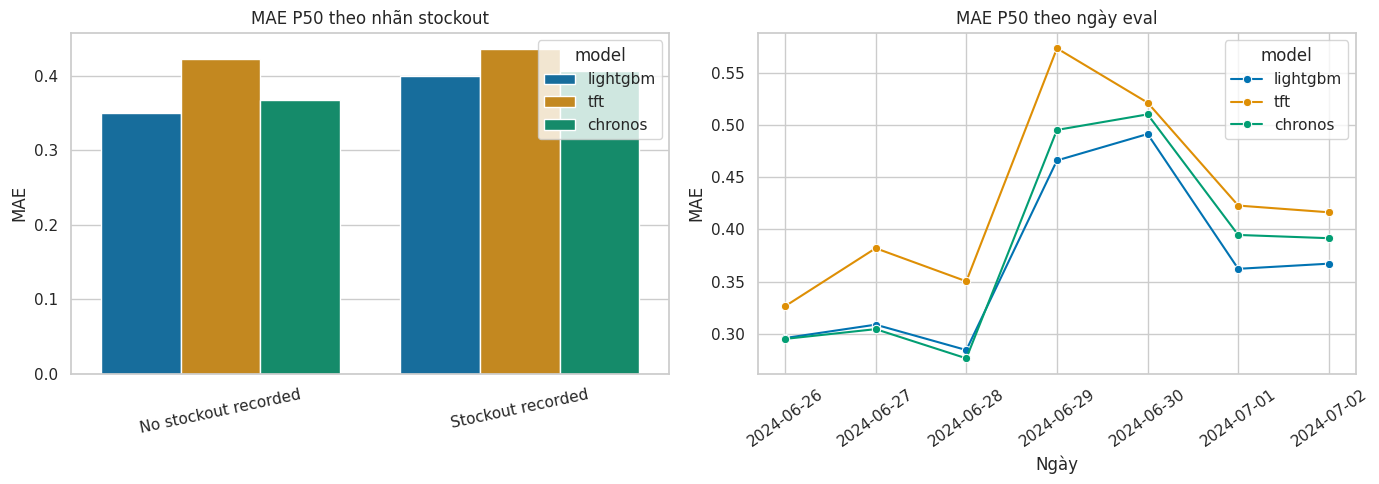

In [18]:
by_status = pd.read_csv('results/metrics_by_stockout.csv')
by_date = pd.read_csv('results/metrics_by_date.csv')
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.barplot(data=by_status,x='stockout_status',y='mae_p50',hue='model',ax=axes[0])
sns.lineplot(data=by_date,x='dt',y='mae_p50',hue='model',marker='o',ax=axes[1])
axes[0].set(title='MAE P50 theo nhãn stockout',xlabel='',ylabel='MAE'); axes[0].tick_params(axis='x',rotation=12)
axes[1].set(title='MAE P50 theo ngày eval',xlabel='Ngày',ylabel='MAE'); axes[1].tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.show()

## 9. Tải kết quả và đẩy mã lên GitHub

Repository đề xuất: `freshretailnet50k-forecasting`. Chưa có URL repository trong dữ liệu đầu vào; sau khi tạo repository, thay URL thật vào lệnh dưới đây. Commit mã, notebook, requirements, README và EDA; không commit Parquet gốc hoặc token. Raw data được downloader tải từ nguồn chính thức và xác minh hash.

In [19]:
# Tạo gói tái lập gồm dữ liệu, mã đã vá seed, lock thư viện và kết quả lượt chạy mới.
import shutil
from pathlib import Path

package_zip = Path('/content/FreshRetailNet50K_Reproducible_Run.zip')
staging = Path('/content/FreshRetailNet50K_Reproducible_Package')
if package_zip.exists(): package_zip.unlink()
if staging.exists(): shutil.rmtree(staging)
shutil.copytree(PROJECT, staging)

# Không đưa báo cáo/notebook cũ trong ZIP nguồn vào gói chạy chuẩn.
for stale in [staging/'FreshRetailNet_Colab.ipynb', staging/'Bao_cao_ca_nhan_FreshRetailNet50K.docx']:
    if stale.exists(): stale.unlink()
(staging/'README.md').write_text(
    '# FreshRetailNet-50K: gói dữ liệu, mã nguồn và kết quả thực nghiệm\n\n'
    'Gói này chứa dữ liệu Parquet gốc, mã nguồn đã cố định seed Chronos, `requirements-colab-lock.txt` và `results/` của lượt chạy chuẩn.\n'
    'Notebook Colab và báo cáo Word mới nhất được gửi riêng. Để chạy lại, tải ZIP này lên notebook Colab và chạy các ô từ đầu.\n'
    'Kết quả chỉ có thể tái lập sát nhất khi dùng cùng phiên bản Python, thư viện, model revision và loại phần cứng.\n',
    encoding='utf-8')
(staging/'PACKAGE_MANIFEST.txt').write_text(
    'FreshRetailNet-50K reproducibility run package\n'
    'Includes official train/eval Parquet, patched source, package lock, run manifests, metrics, predictions, reports, and figures.\n'
    'The current Colab notebook and Word report are delivered separately.\n',
    encoding='utf-8')
shutil.make_archive(str(package_zip.with_suffix('')), 'zip', root_dir=staging.parent, base_dir=staging.name)
print('Đã tạo gói chuẩn:', package_zip)
print('Gói chứa requirements-colab-lock.txt và results/ của lượt chạy mới.')
print('Notebook và Word được gửi riêng; không có bản cũ nằm lẫn trong ZIP.')

Đã tạo gói chuẩn: /content/FreshRetailNet50K_Reproducible_Run.zip
Gói chứa requirements-colab-lock.txt và results/ của lượt chạy mới.
Notebook và Word được gửi riêng; không có bản cũ nằm lẫn trong ZIP.


## Phạm vi và giới hạn khi diễn giải

`stock_hour6_22_cnt > 0` nghĩa là có ghi nhận ít nhất một giờ hết hàng trong khung 06:00–22:00. Dữ liệu không cho biết chính xác số đơn/nhu cầu bị mất. Chênh lệch metric giữa hai nhãn là mô tả, không chứng minh quan hệ nhân quả. `sale_amount` chuẩn hóa toàn cục nên không gọi là số lượng vật lý. Coverage 80% cần đọc cùng độ rộng P10–P90.